# 02 — Gender equality: presentation charts in English

**18 graphiques en anglais**, avec exports PNG 16:9 à 300 DPI et SVG. Les six graphiques essentiels sont signalés **CORE** ; les autres servent au contexte ou aux annexes.

**Périmètre :** toute la base originale, 1 518 salariés, dont 605 femmes et 913 hommes. Les analyses salariales de `reports/` utilisent parfois seulement l’entraînement : leurs chiffres ne sont pas interchangeables avec les descriptifs ci-dessous.

Les écarts observés ne prouvent ni causalité ni discrimination. La période, la devise, le temps de travail et le dictionnaire des scores ne sont pas documentés. Le délai depuis une promotion ne mesure pas le taux d’accès aux promotions.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'src/data.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Project root not found.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown
from src.data import load_data
from src.gender_presentation import OUT, prepare, chart, finish
protected_files = list((ROOT/'data').rglob('*.xlsx')) + list((ROOT/'outputs/models').glob('*'))
protected = {str(p.relative_to(ROOT)): sha256(p.read_bytes()).hexdigest()
             for p in protected_files if p.is_file()}
df = load_data()
state = prepare(df)
display(state['summary'])
print('Historical notebook-02 tables retained. New chart exports:', OUT)

,gender,n,departures,departure_rate,wilson_low,wilson_high,mean_income,median_income
0,Female,605,89,0.147107,0.121110,0.177558,6703.066116,5154.0
1,Male,913,159,0.174151,0.150931,0.200102,6378.242059,4821.0


Historical notebook-02 tables retained. New chart exports: /Users/alexandrelouguet/Desktop/Capgemini Invent/capgemini-invent-ozone/outputs/02_gender_presentation


## Choix pour la présentation

| Graphique | Message à soutenir | Statut |
|---|---|---|
| 02 | Comparaison des départs, avec effectifs et incertitude | CORE |
| 05 | Composition des groupes par niveau | CORE |
| 08 | Représentation dans les métiers | CORE |
| 10 | Écart salarial brut versus standardisé, à couverture explicite | CORE |
| 11 | Écarts salariaux par métier/niveau, petites cellules masquées | CORE |
| 12 | Heures supplémentaires et départs dans chaque genre | CORE |

Sélectionner ces visuels selon le temps disponible ; les 18 graphiques ne doivent pas tous figurer dans le deck principal. Les couleurs sont constantes : **women = dark blue**, **men = cyan**.

## 01 — Context / appendix

Contexte : effectifs et répartition. Ce graphique ne démontre pas à lui seul un déséquilibre de recrutement.

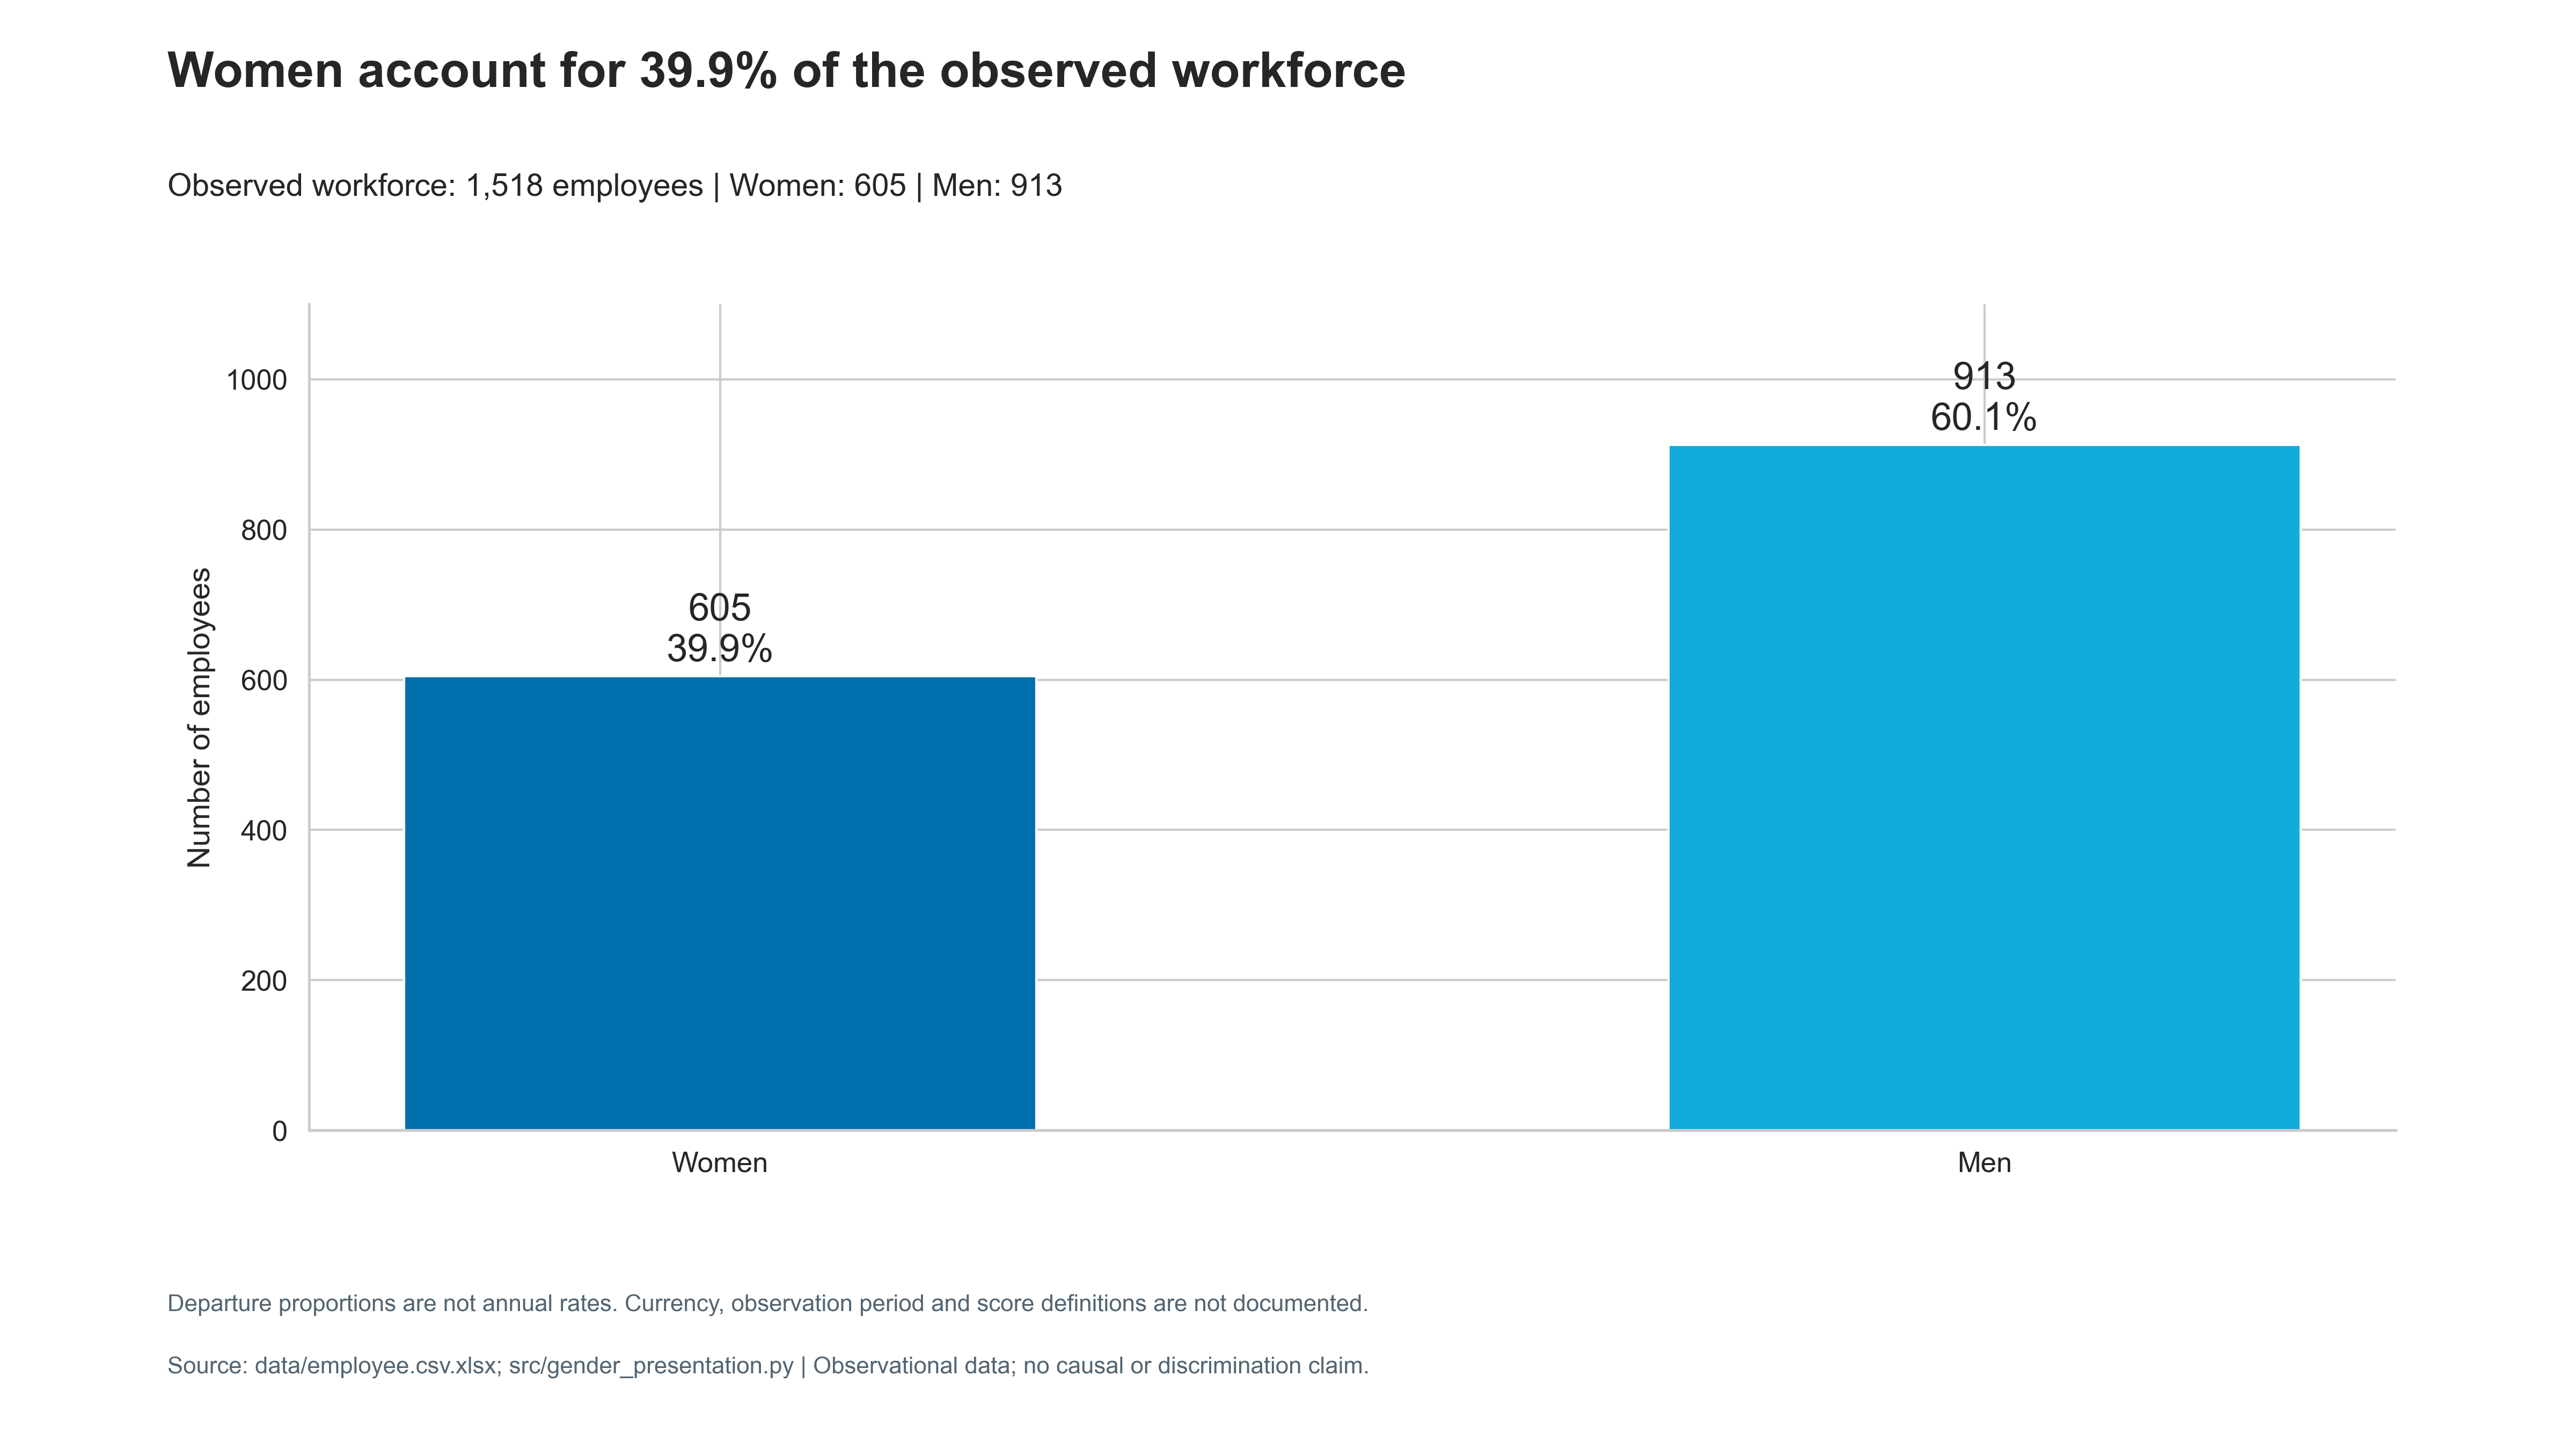

In [2]:
chart(state, 1)

## 02 — CORE presentation chart

**CORE.** Proportions observées et IC Wilson 95 %. Les taux ne sont pas annualisés et les populations ne sont pas ajustées.

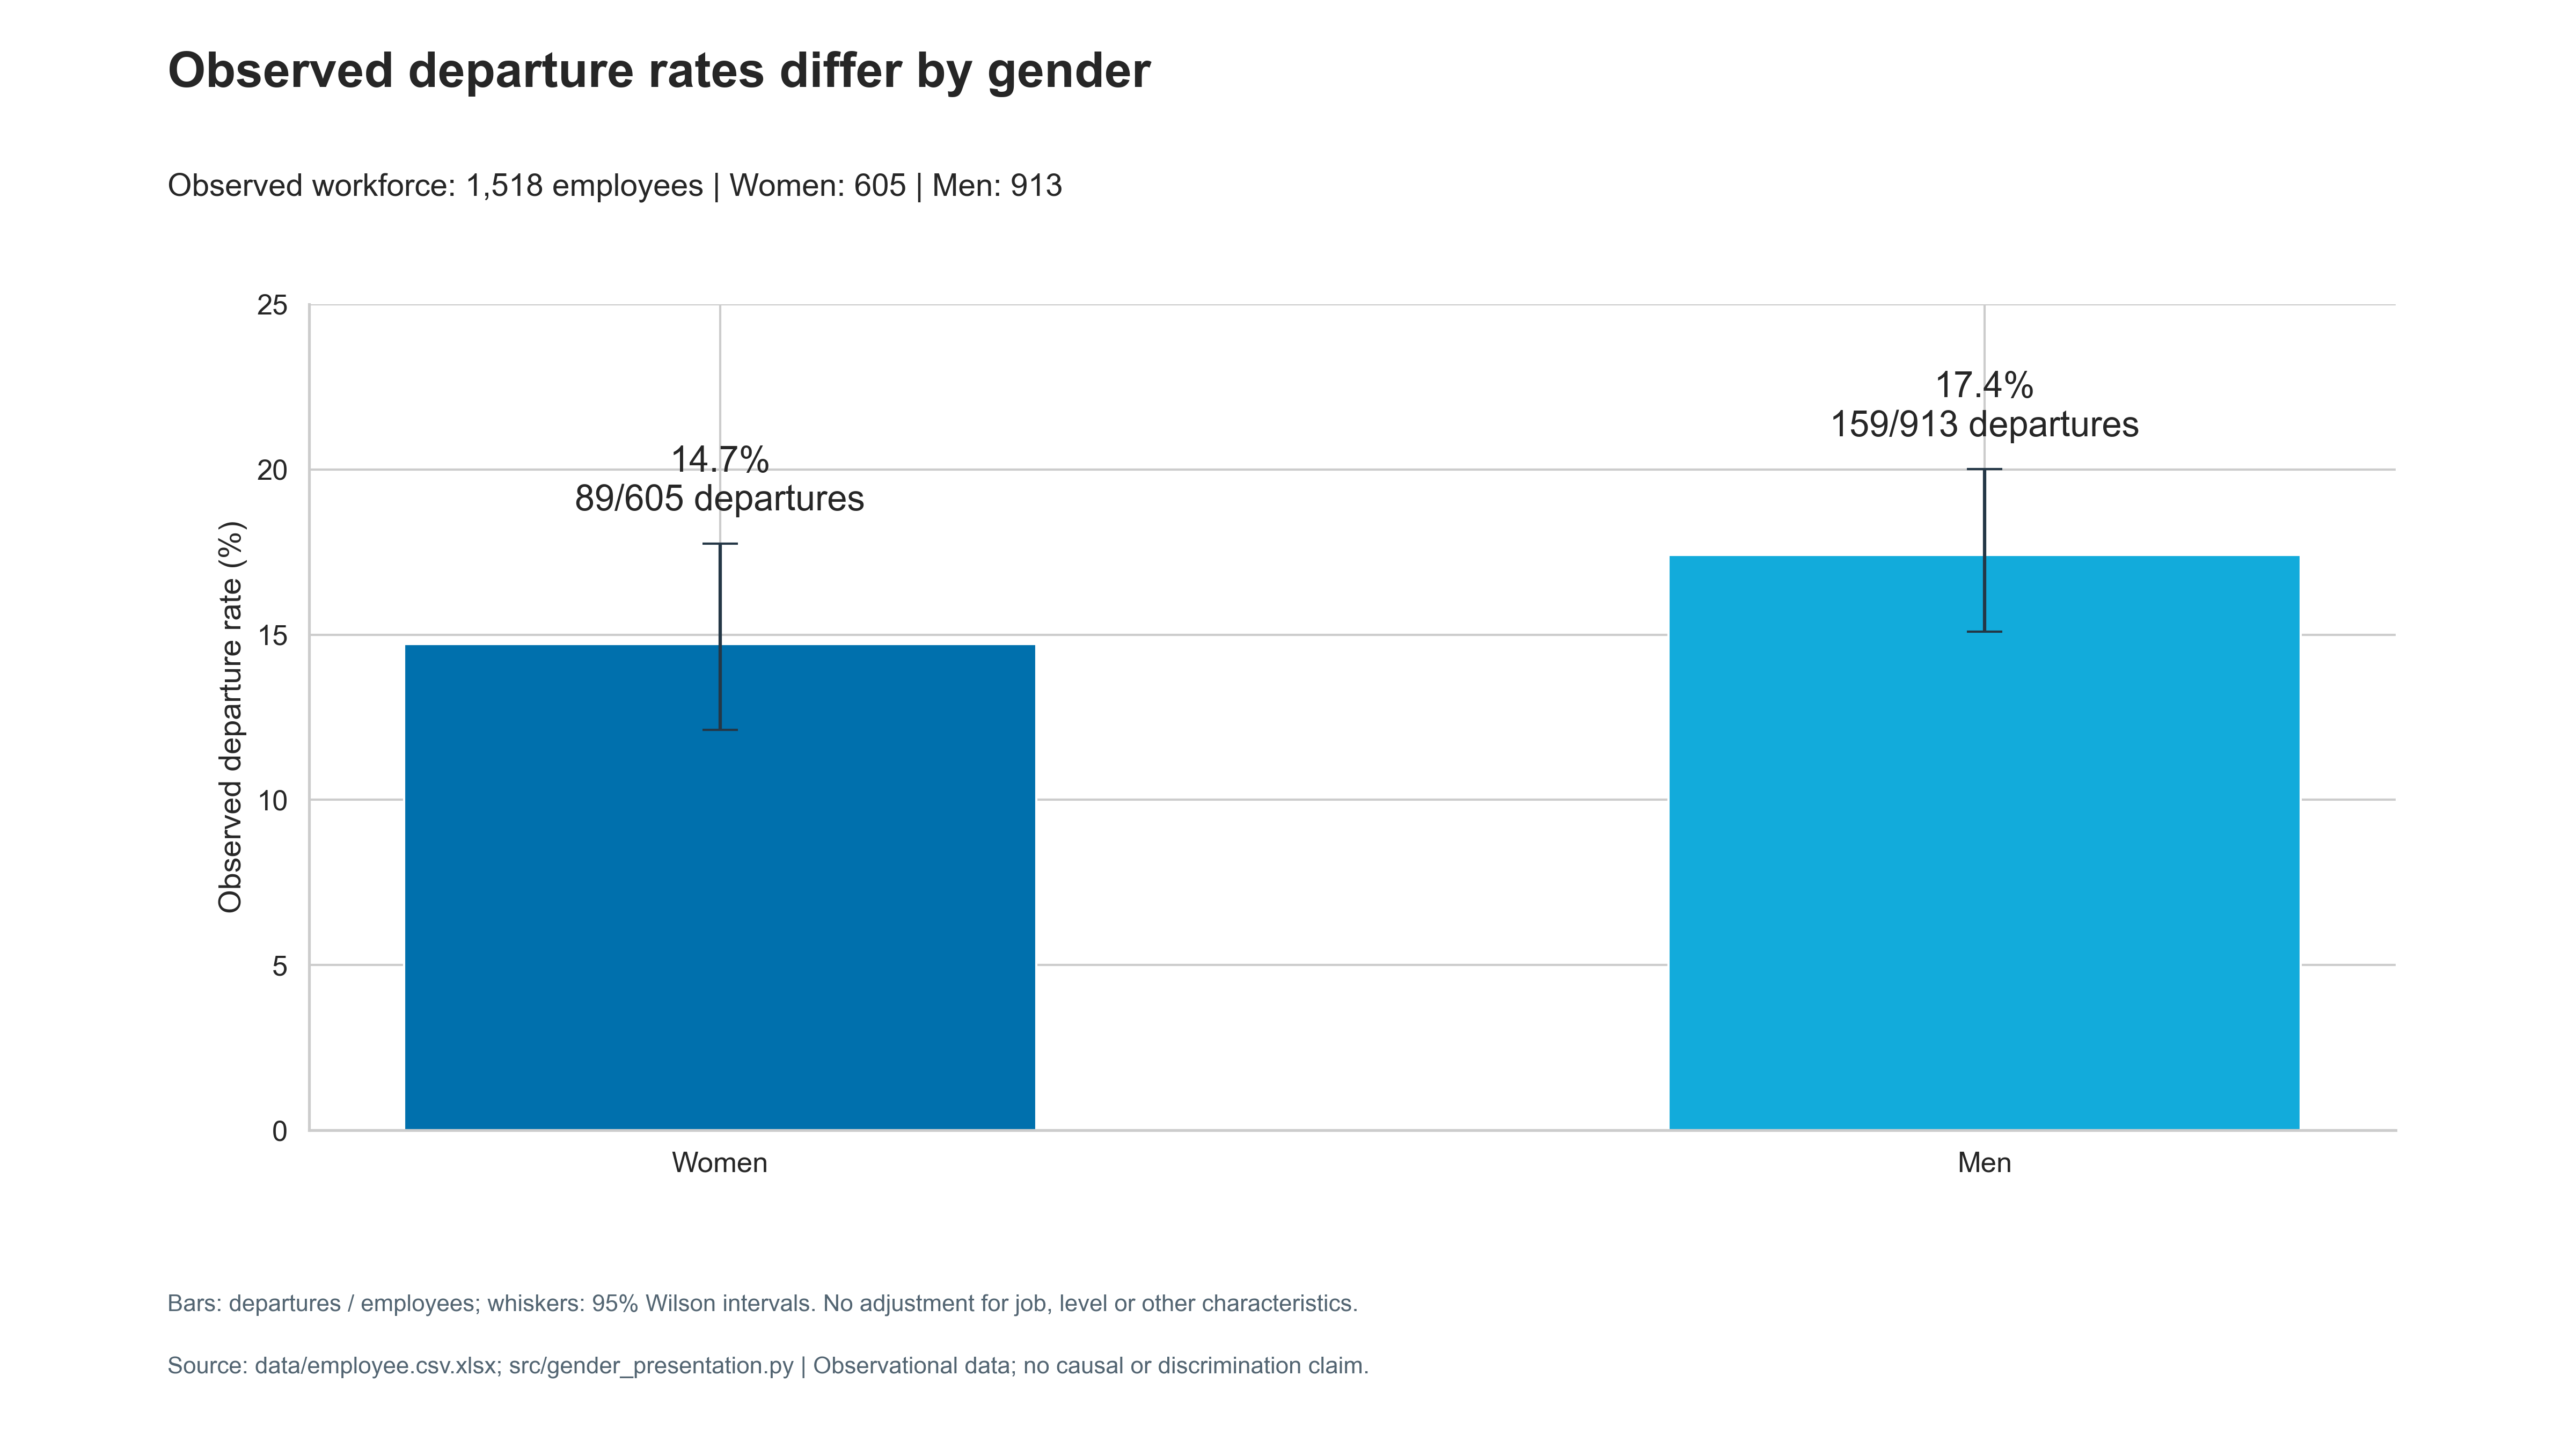

In [3]:
chart(state, 2)

## 03 — Context / appendix

Distribution du revenu mensuel : conserver les extrêmes et ne pas inventer de devise.

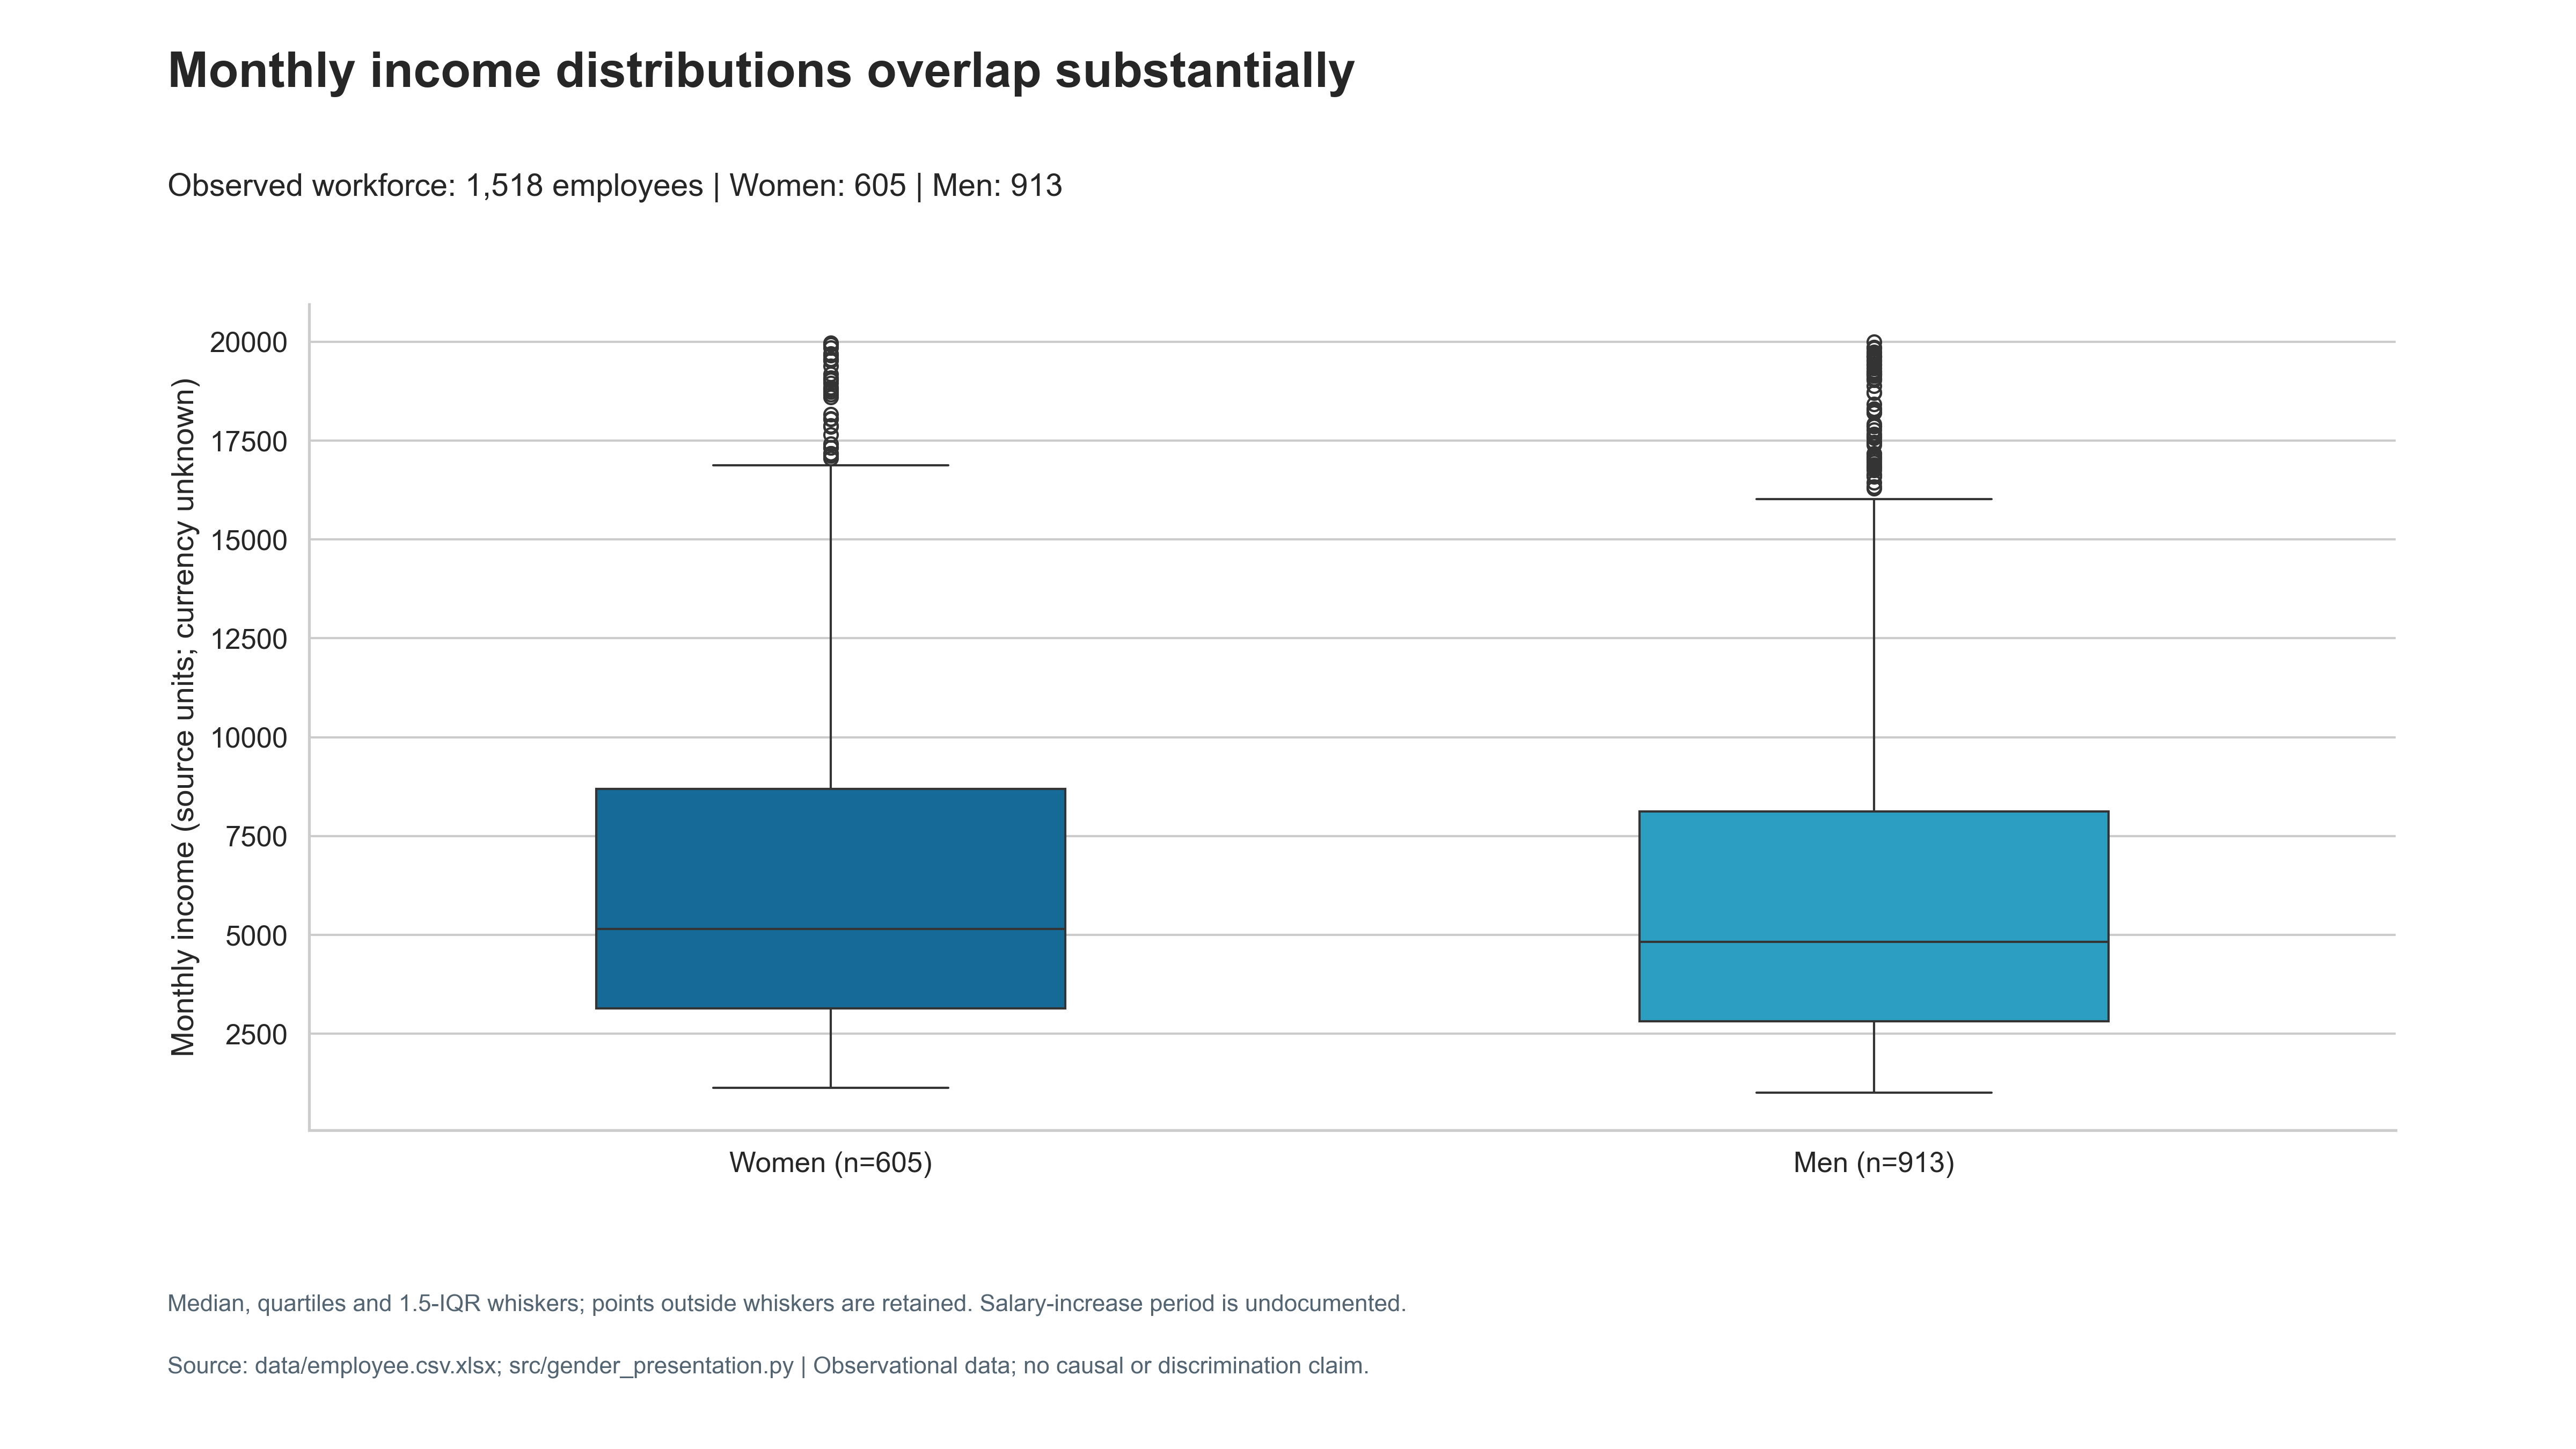

In [4]:
chart(state, 3)

## 04 — Context / appendix

Moyenne et médiane apportent deux lectures complémentaires ; aucune correction de composition ici.

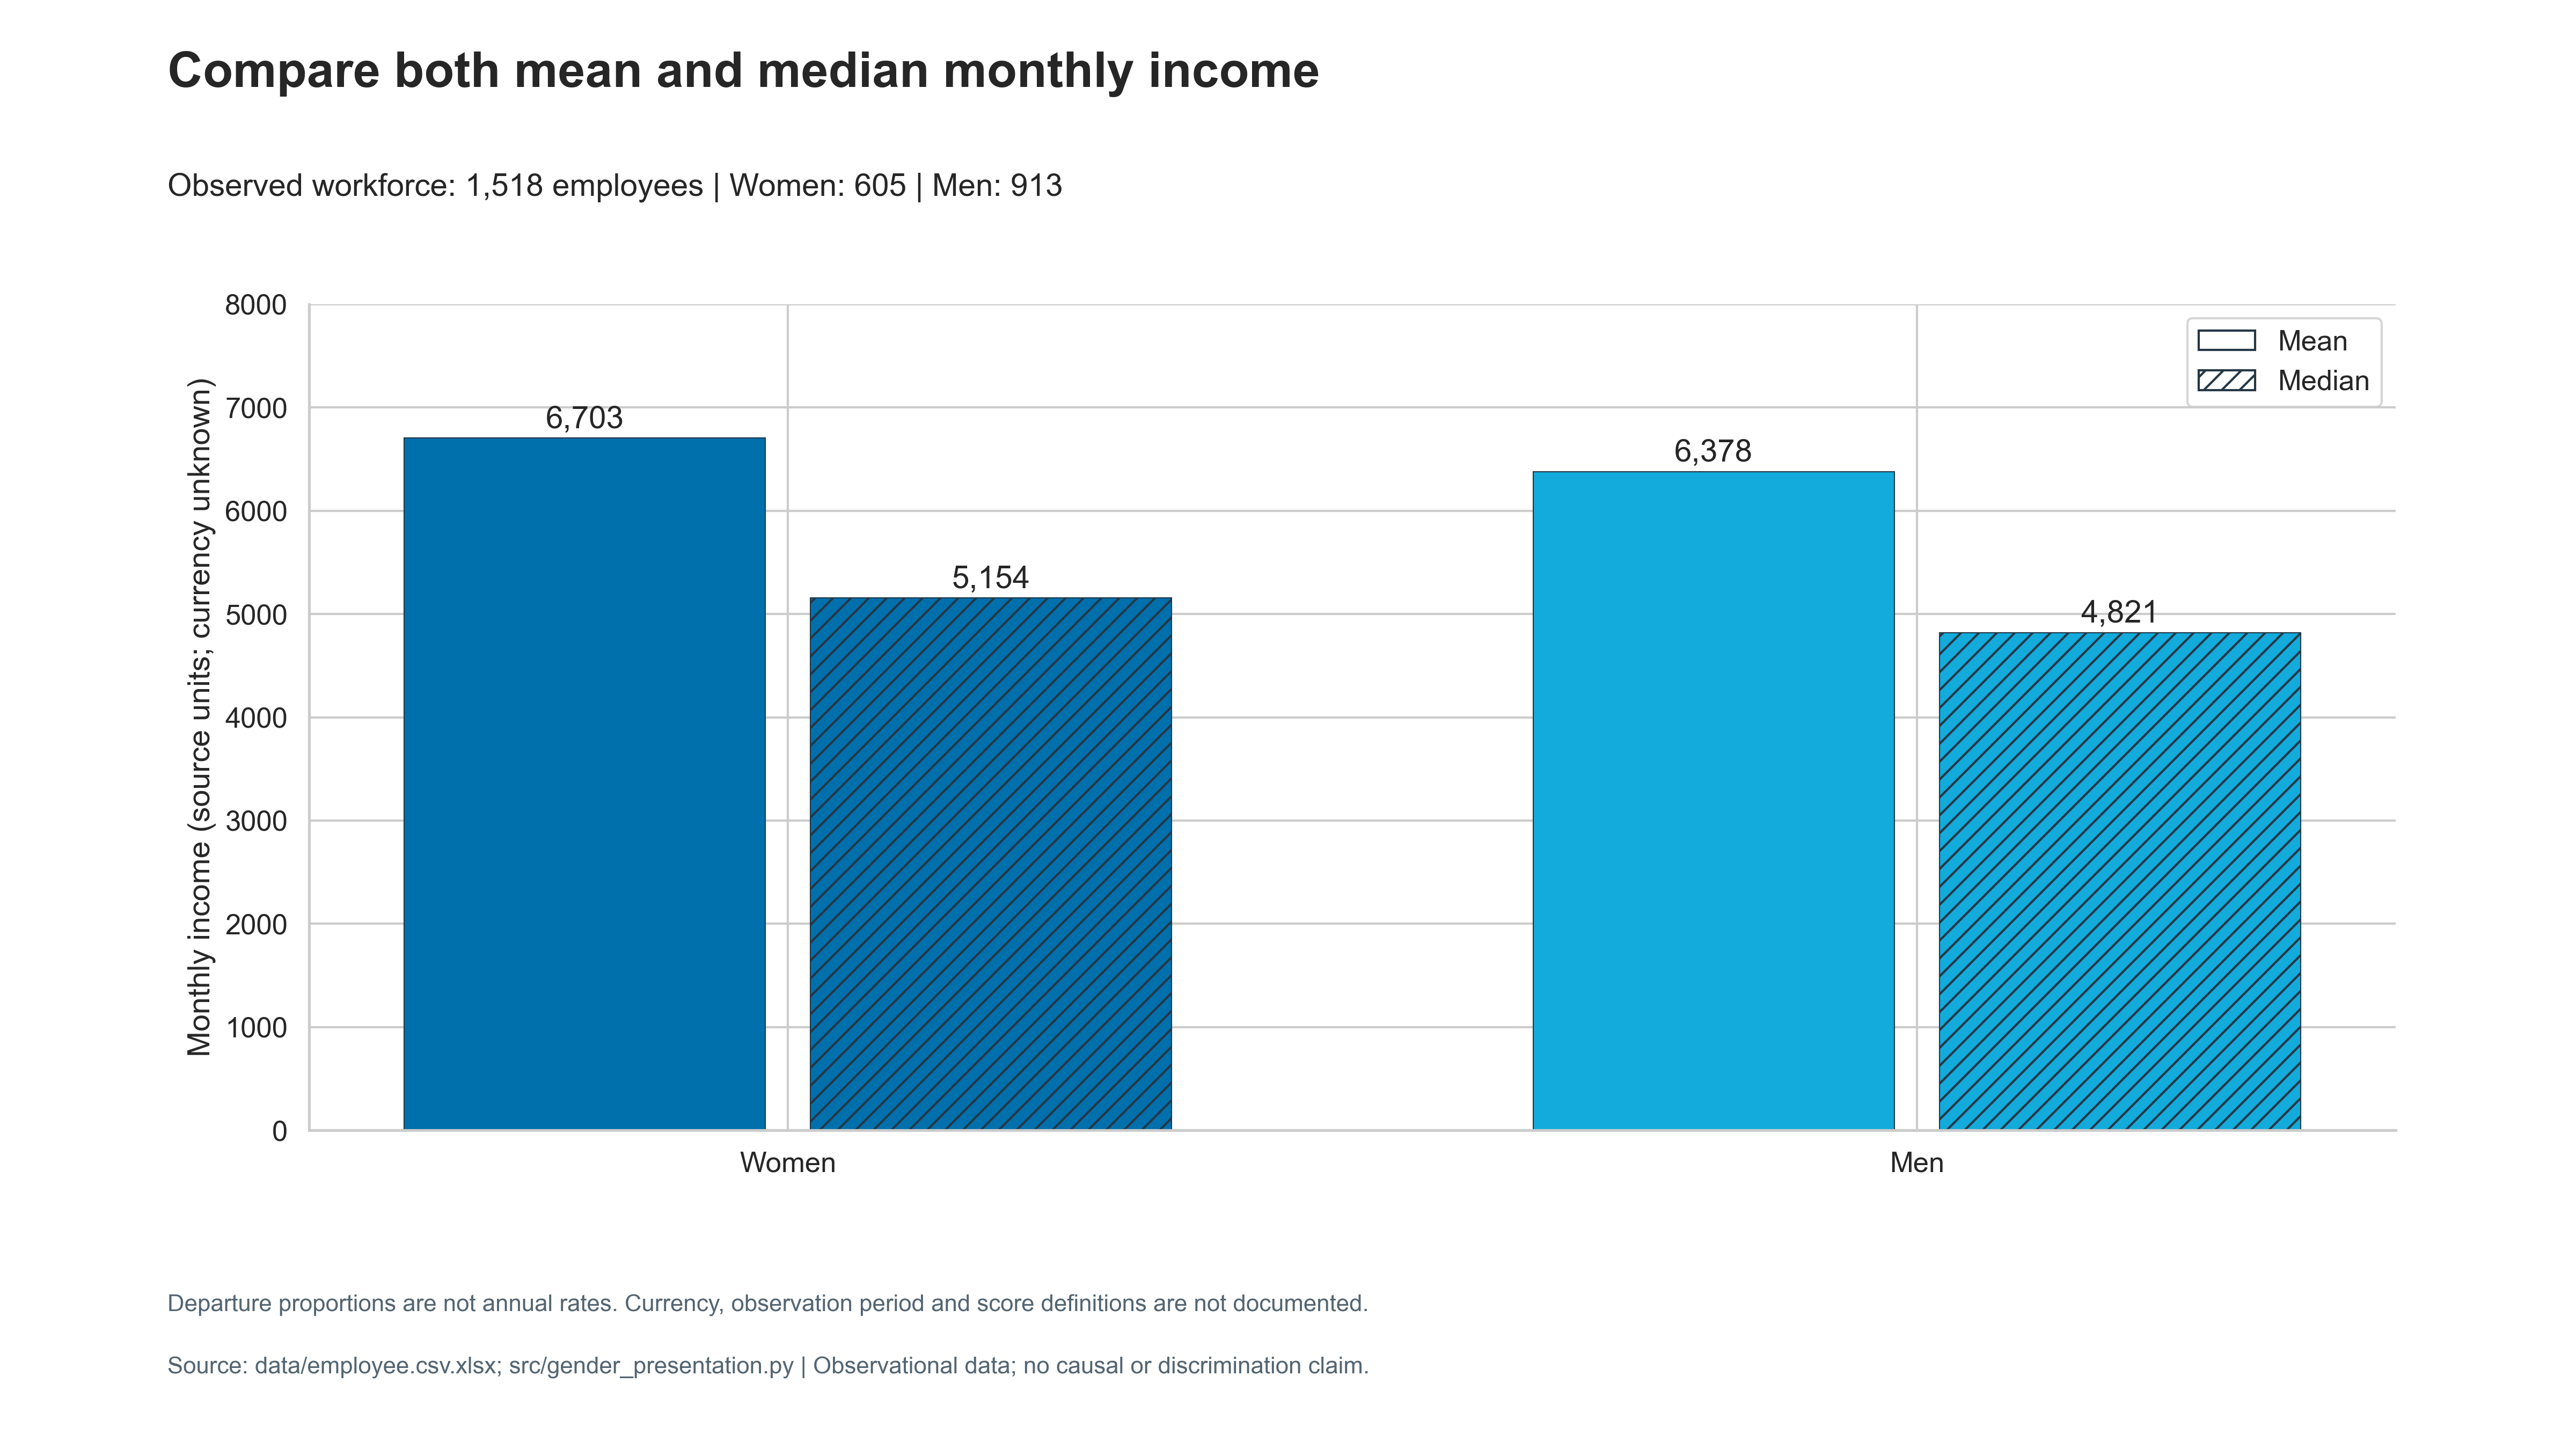

In [5]:
chart(state, 4)

## 05 — CORE presentation chart

**CORE.** Chaque groupe de genre somme à 100 %. Les niveaux sont des codes à valider, pas une définition automatique de séniorité.

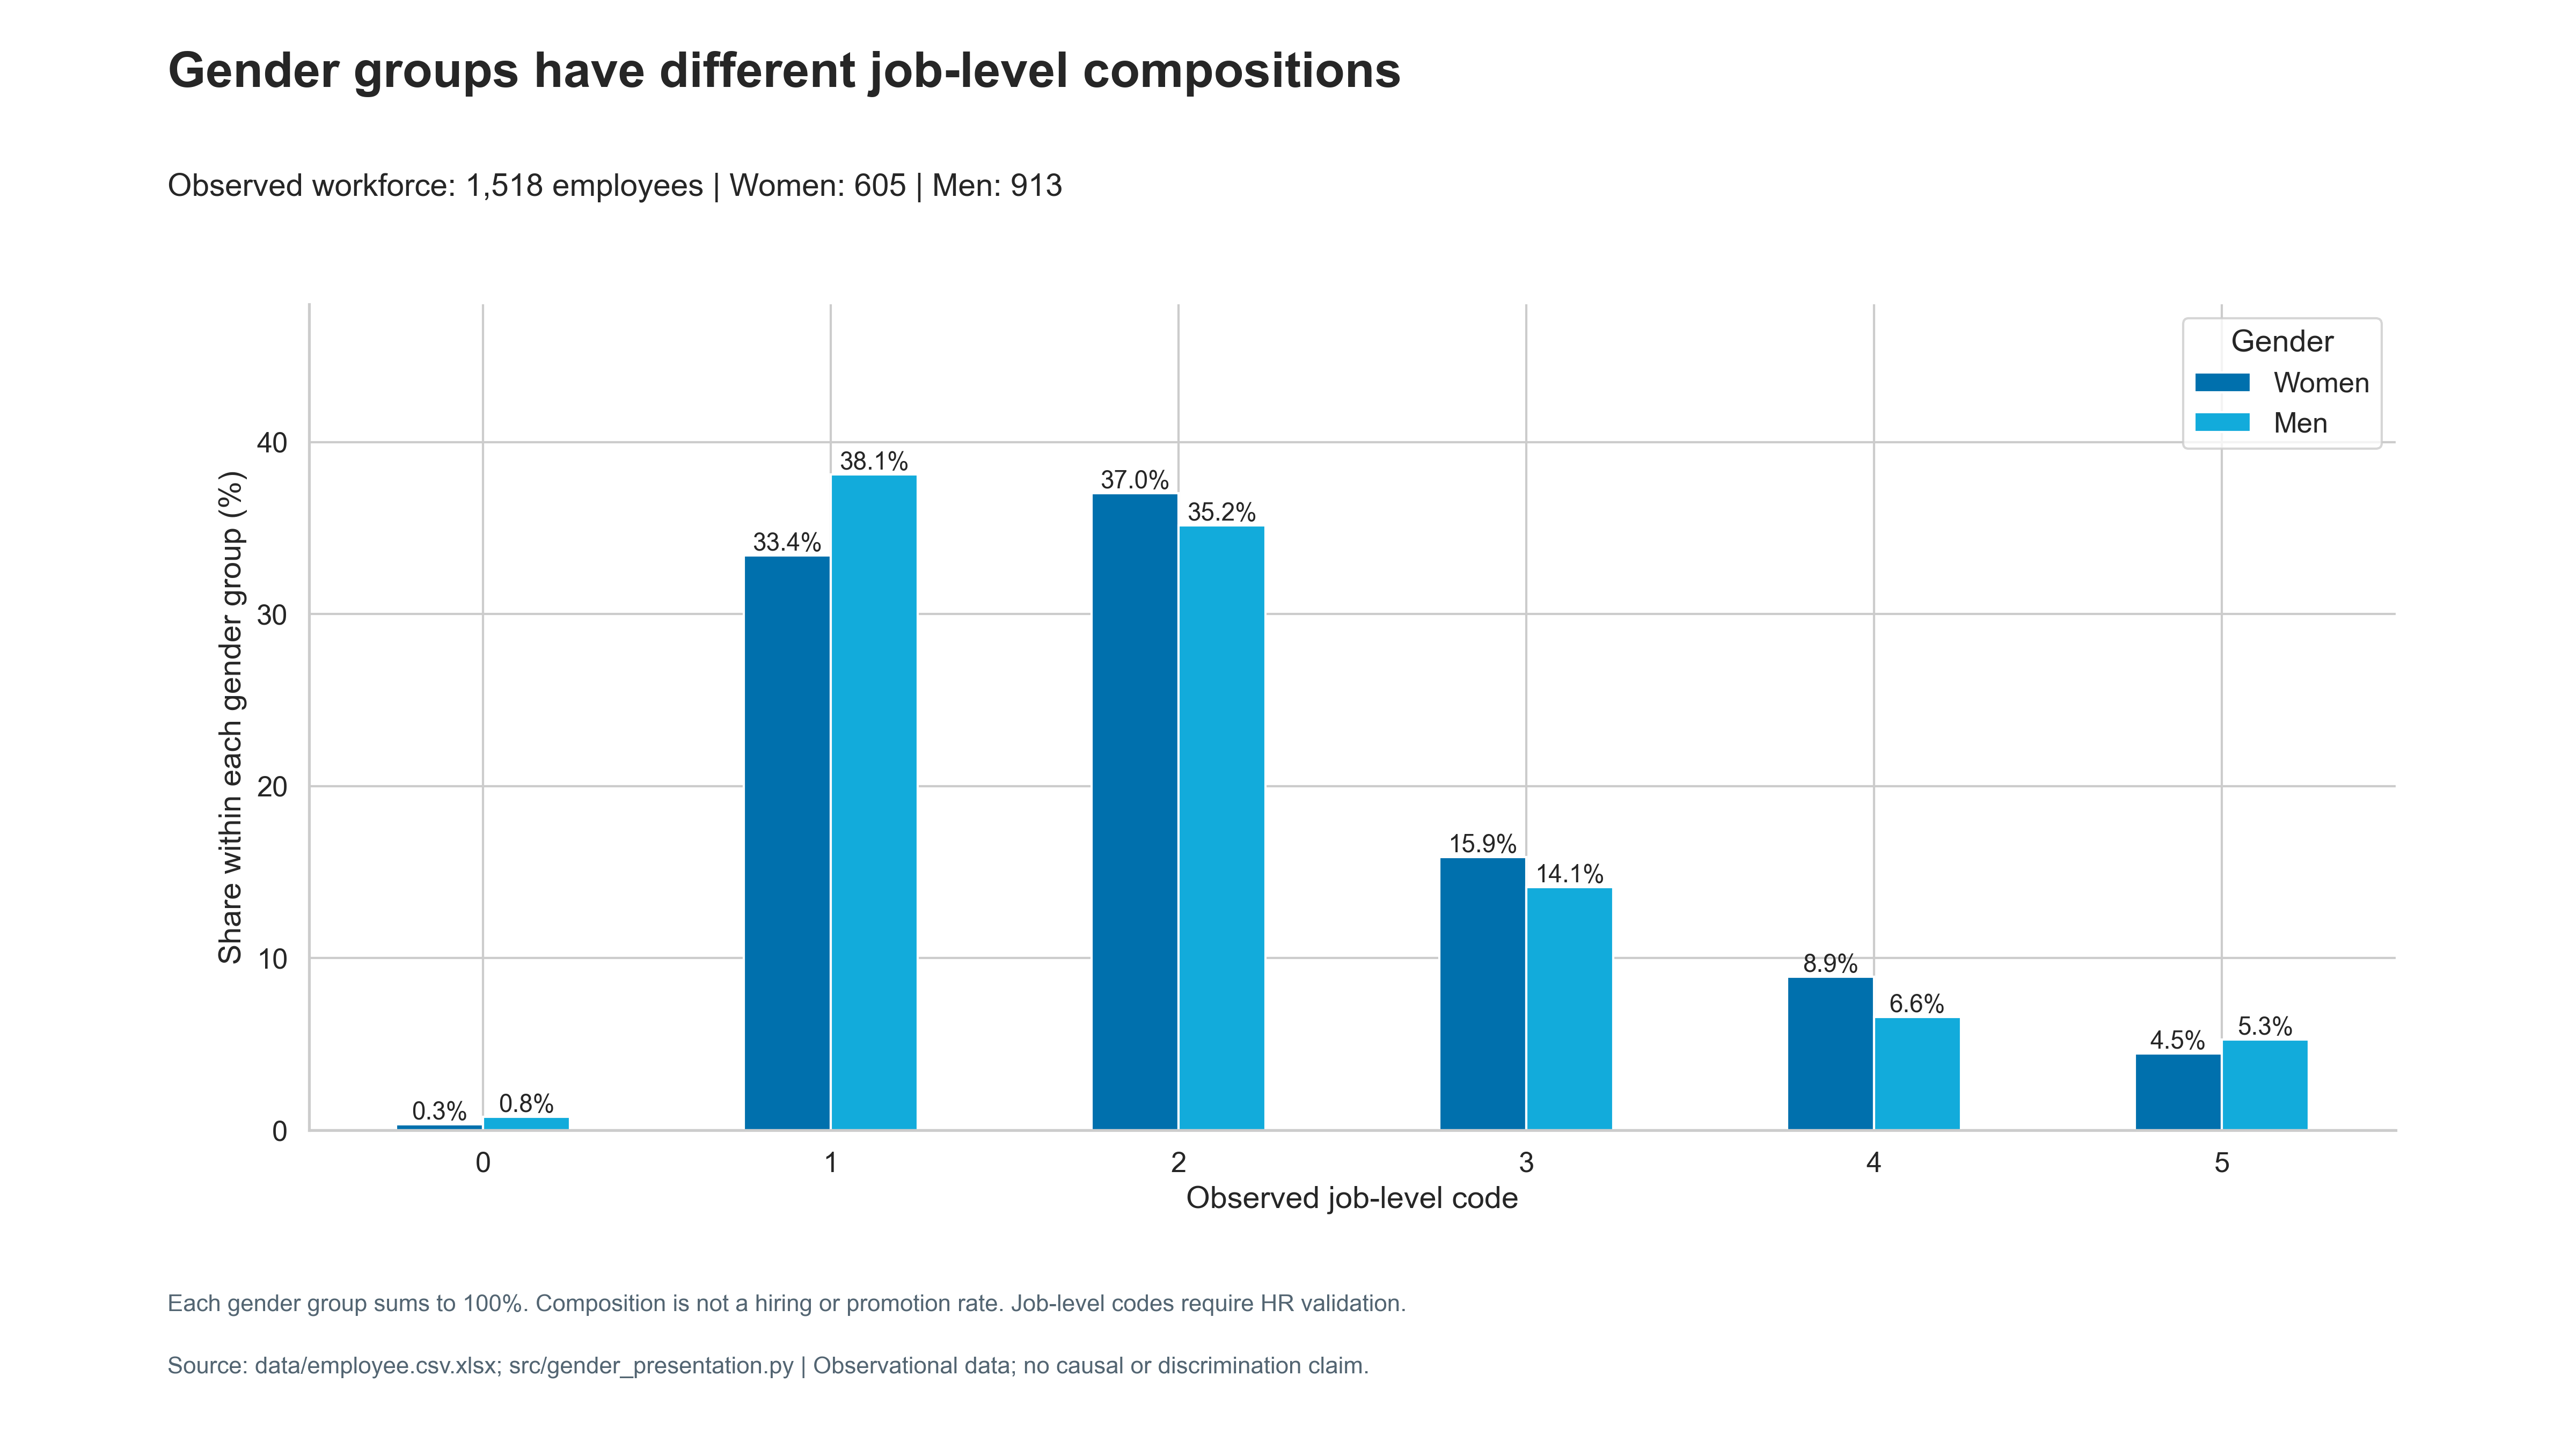

In [6]:
chart(state, 5)

## 06 — Context / appendix

Composition des métiers : comparer des parts au sein de chaque genre, pas seulement les effectifs bruts.

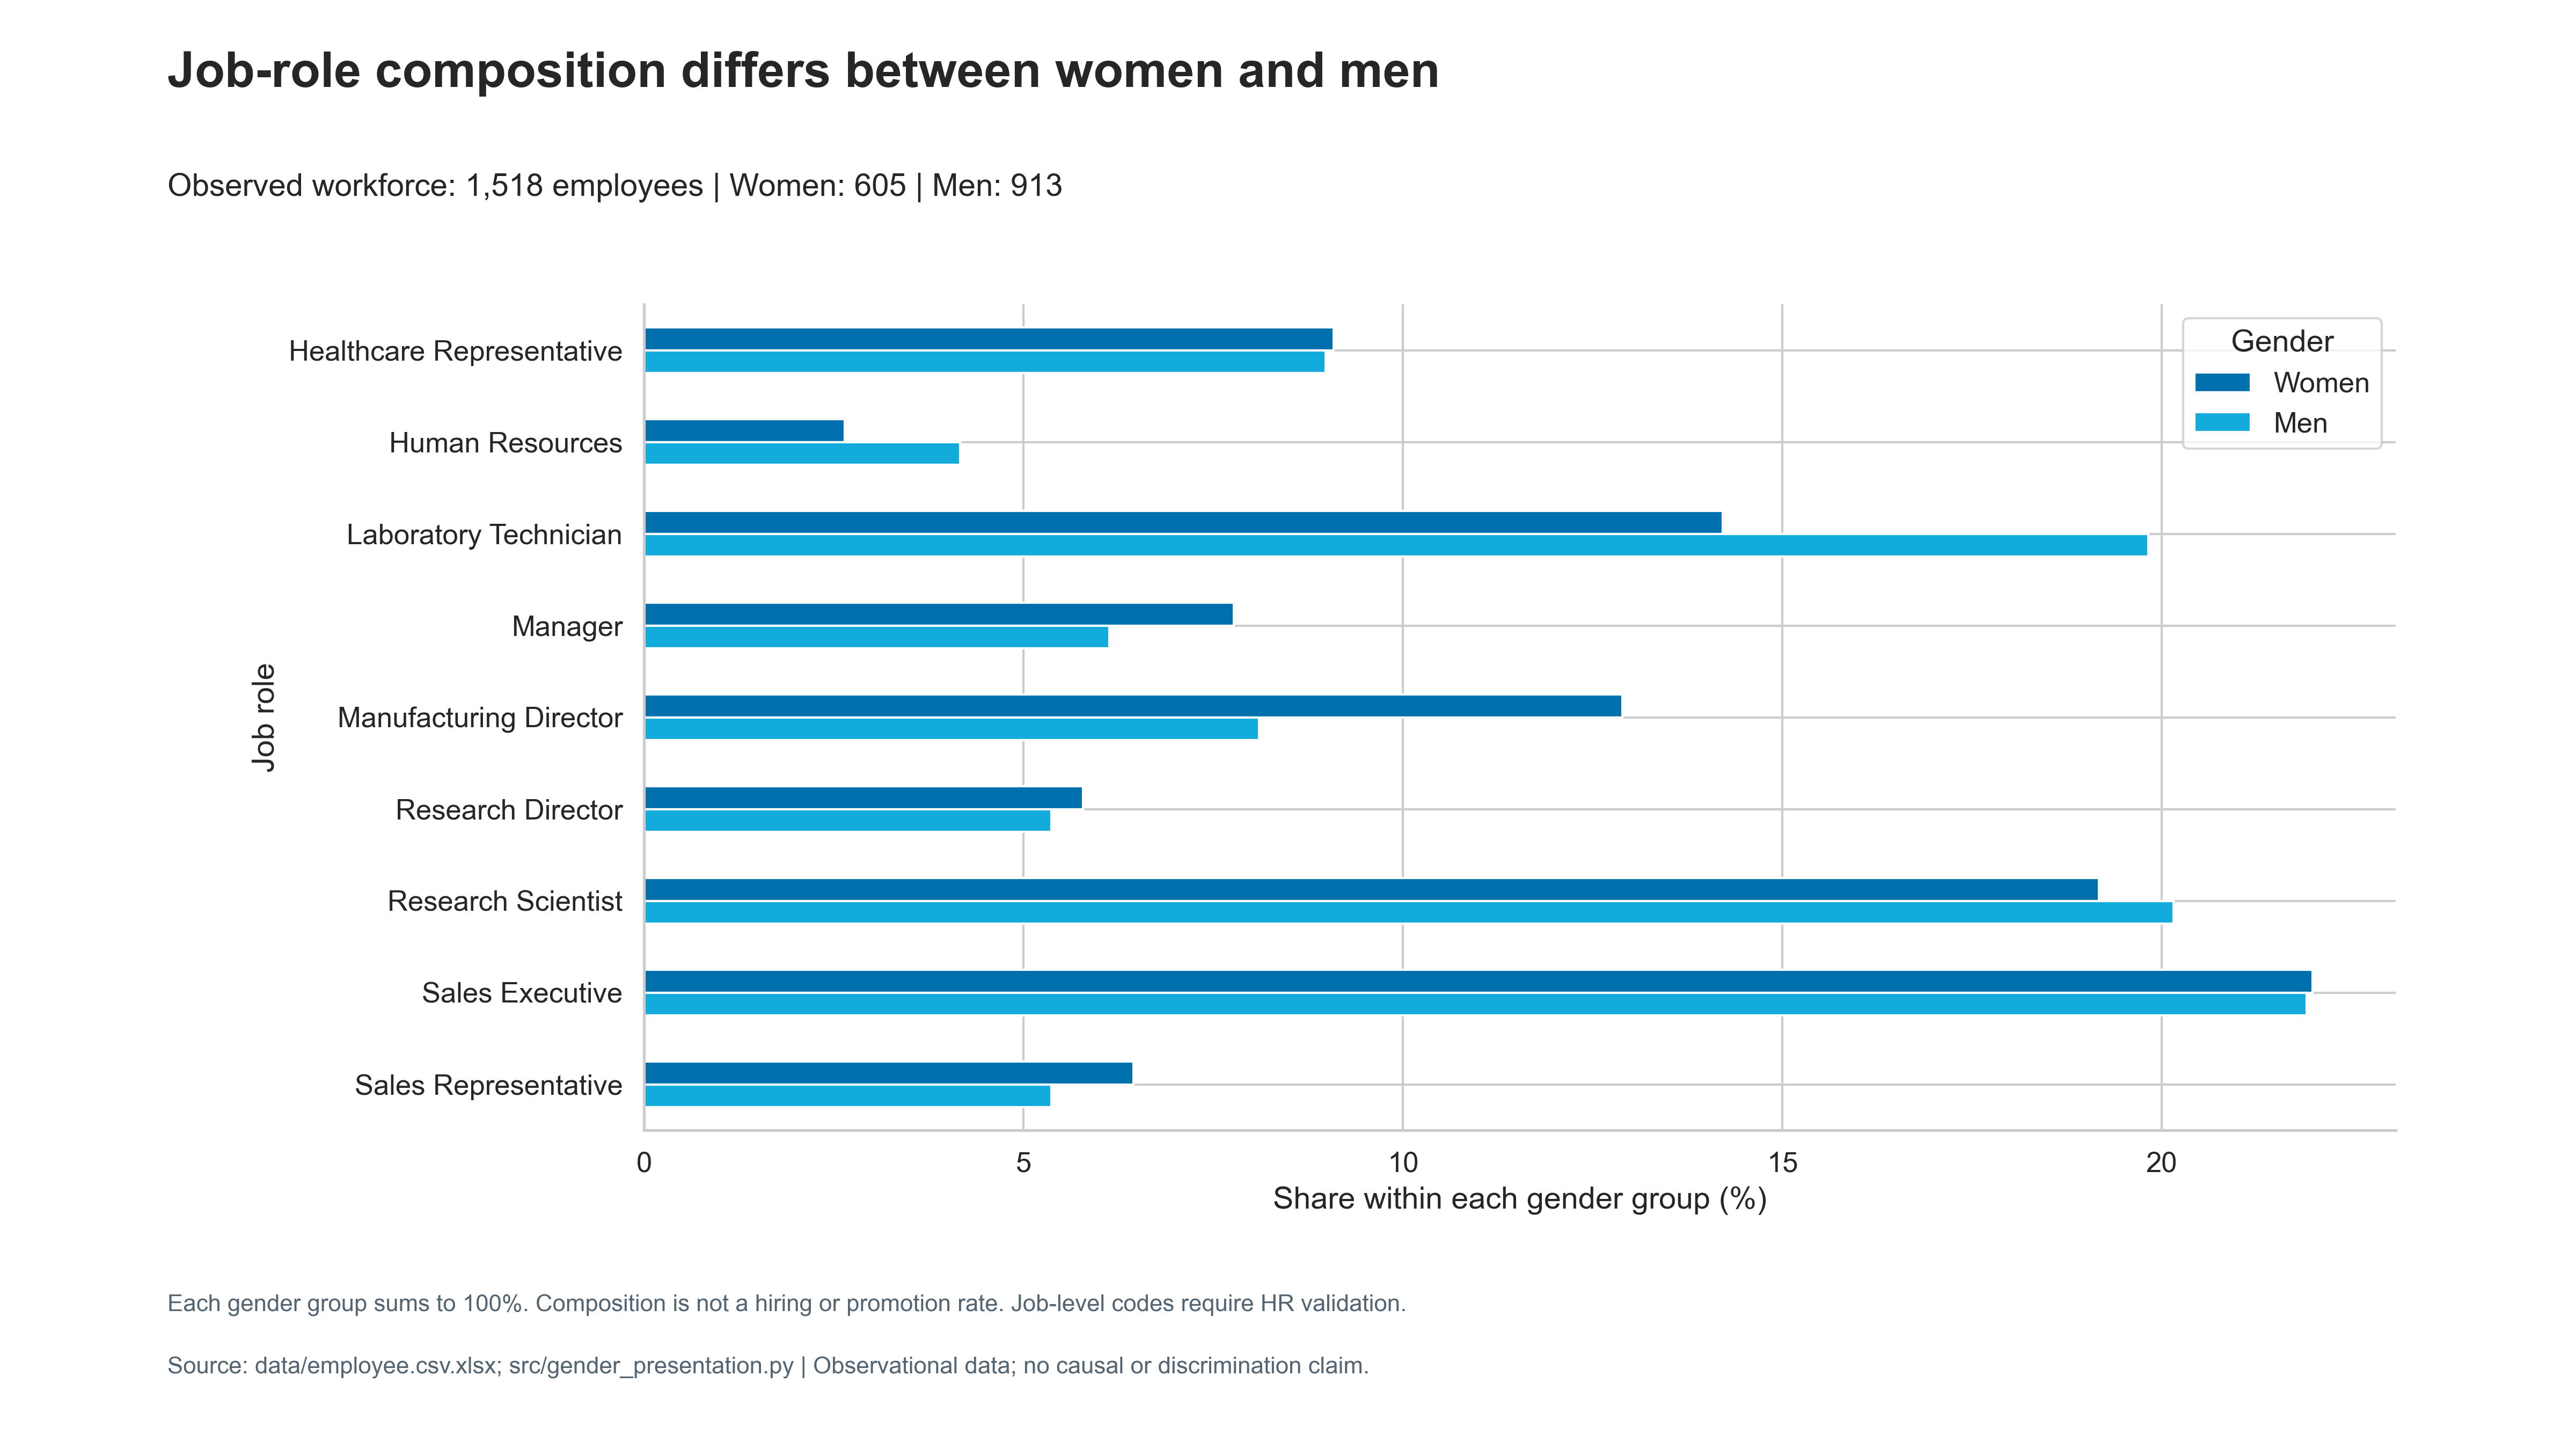

In [7]:
chart(state, 6)

## 07 — Context / appendix

Part de femmes au sein de chaque niveau, avec effectifs et IC. Une petite cellule reste très incertaine.

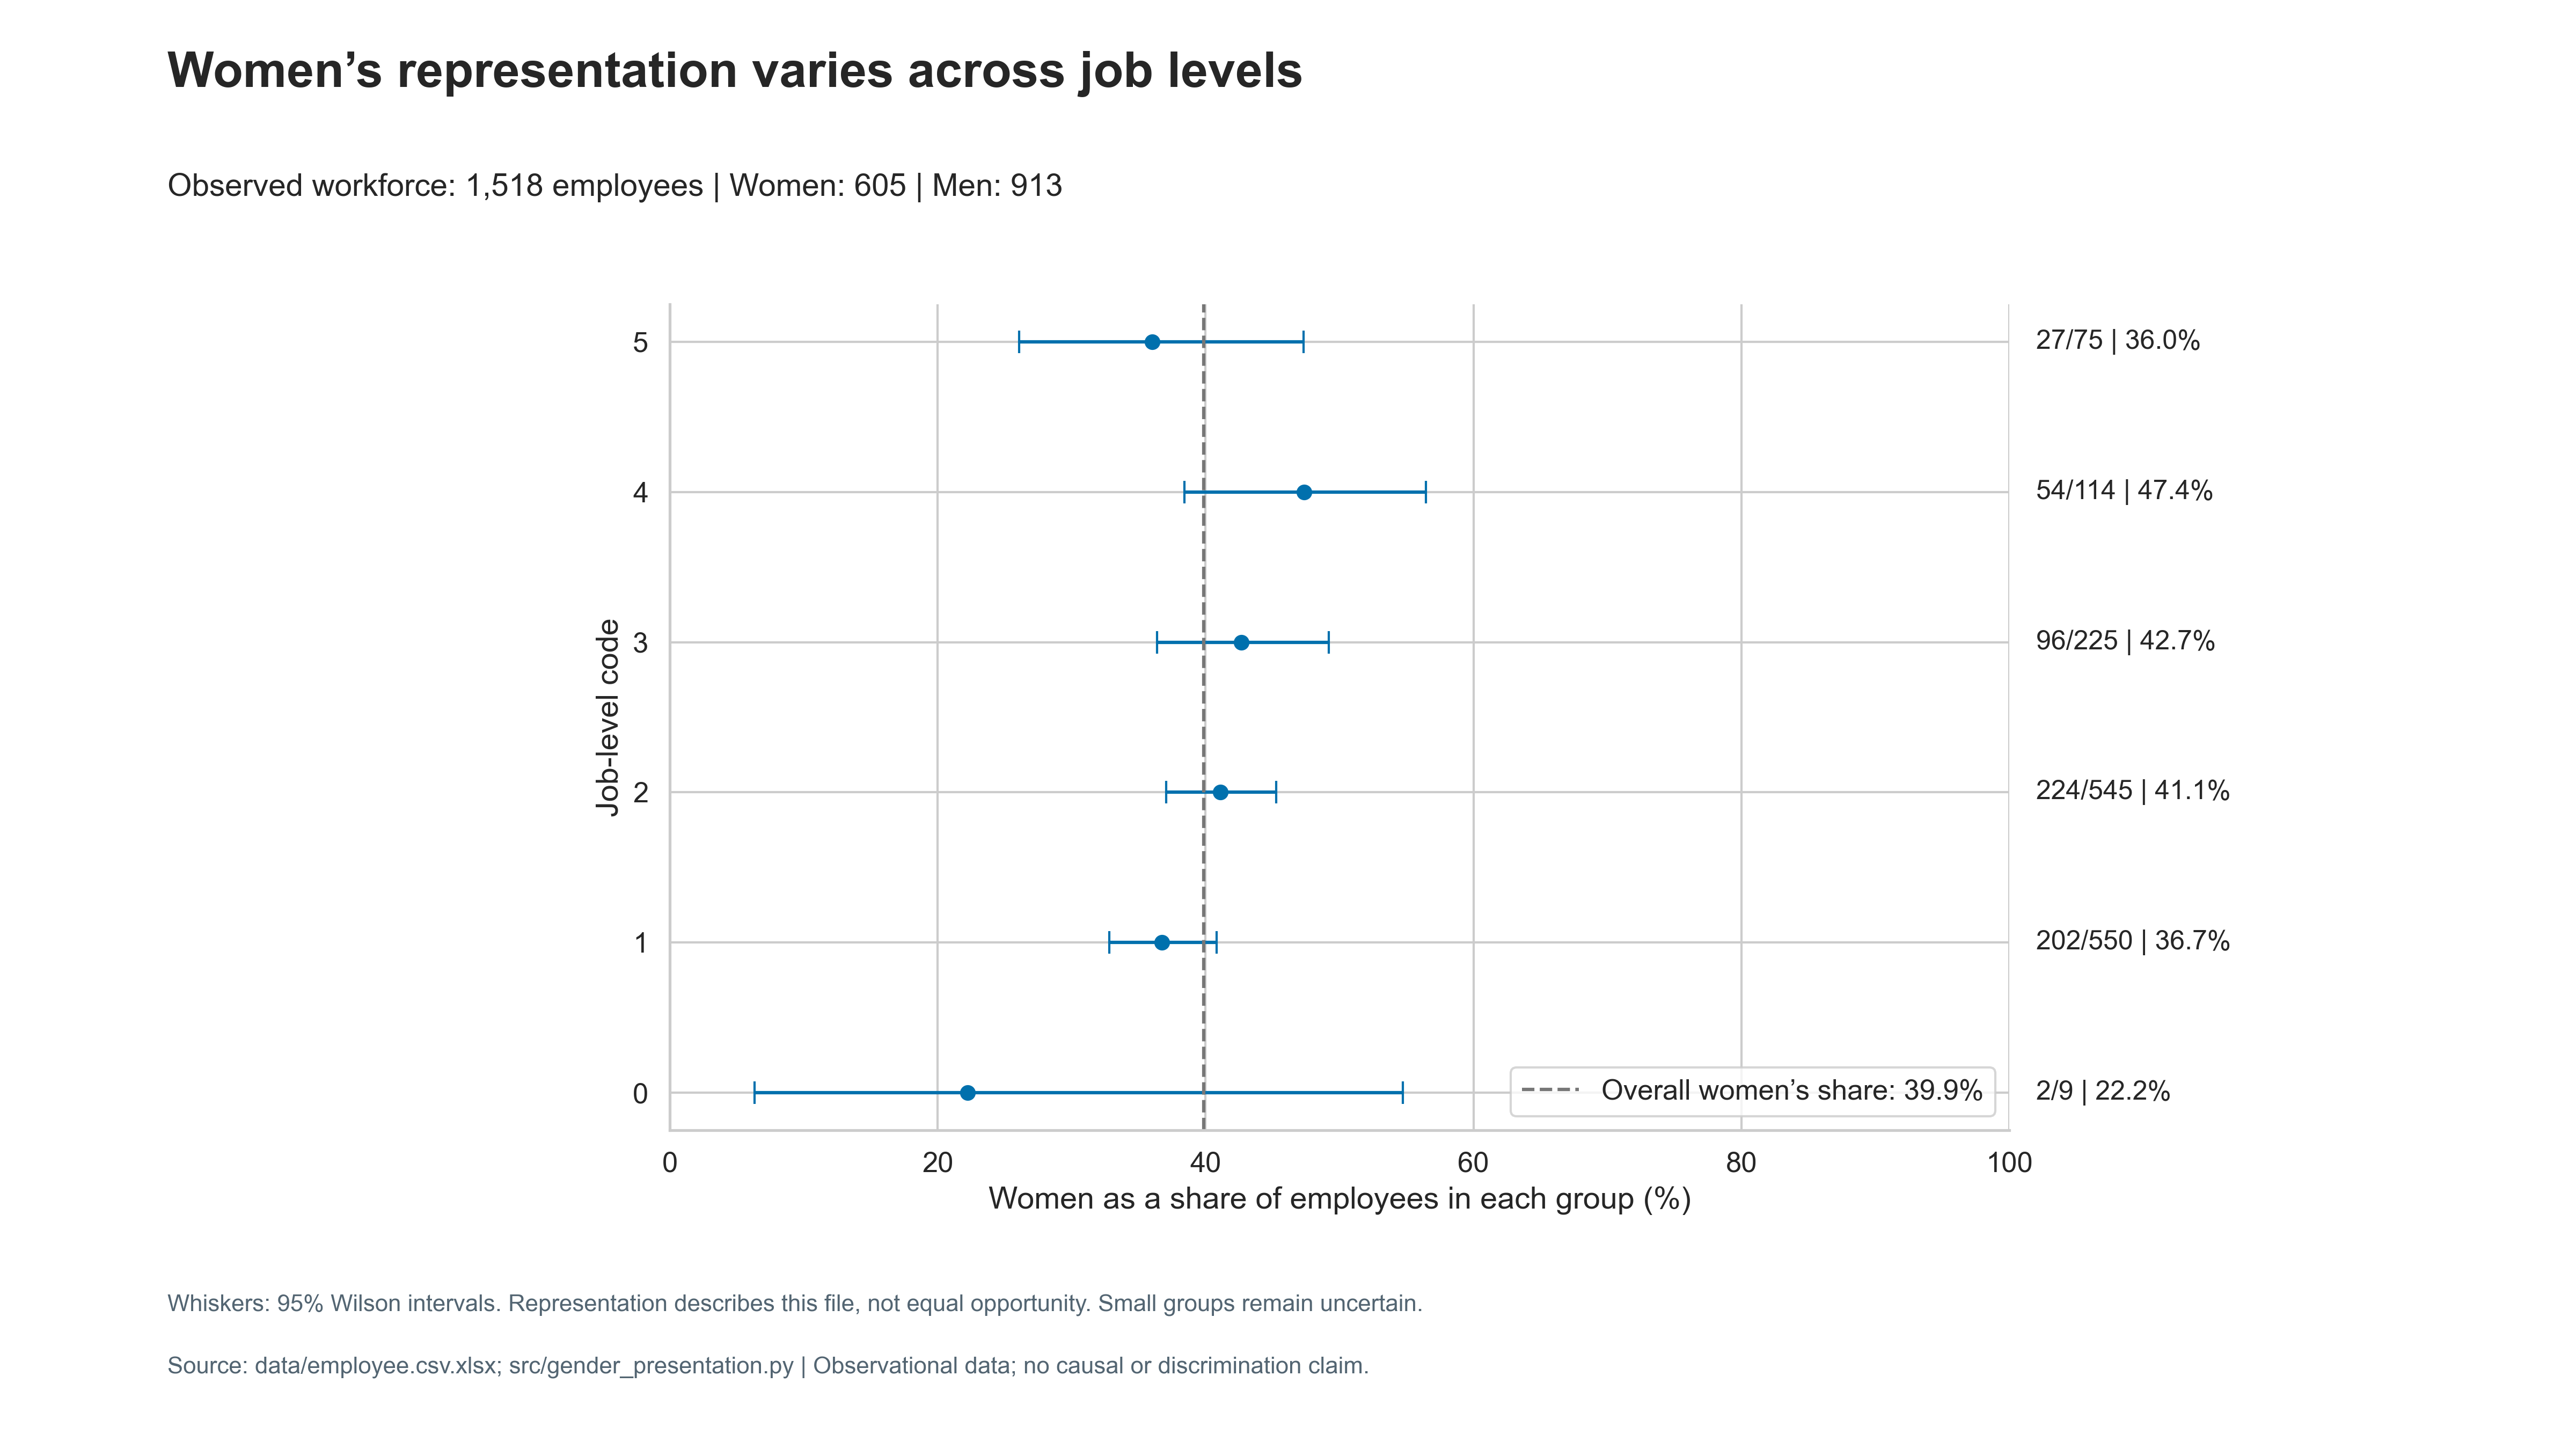

In [8]:
chart(state, 7)

## 08 — CORE presentation chart

**CORE.** Part de femmes par métier versus leur part globale. Une différence de représentation ne prouve pas une différence d’opportunité.

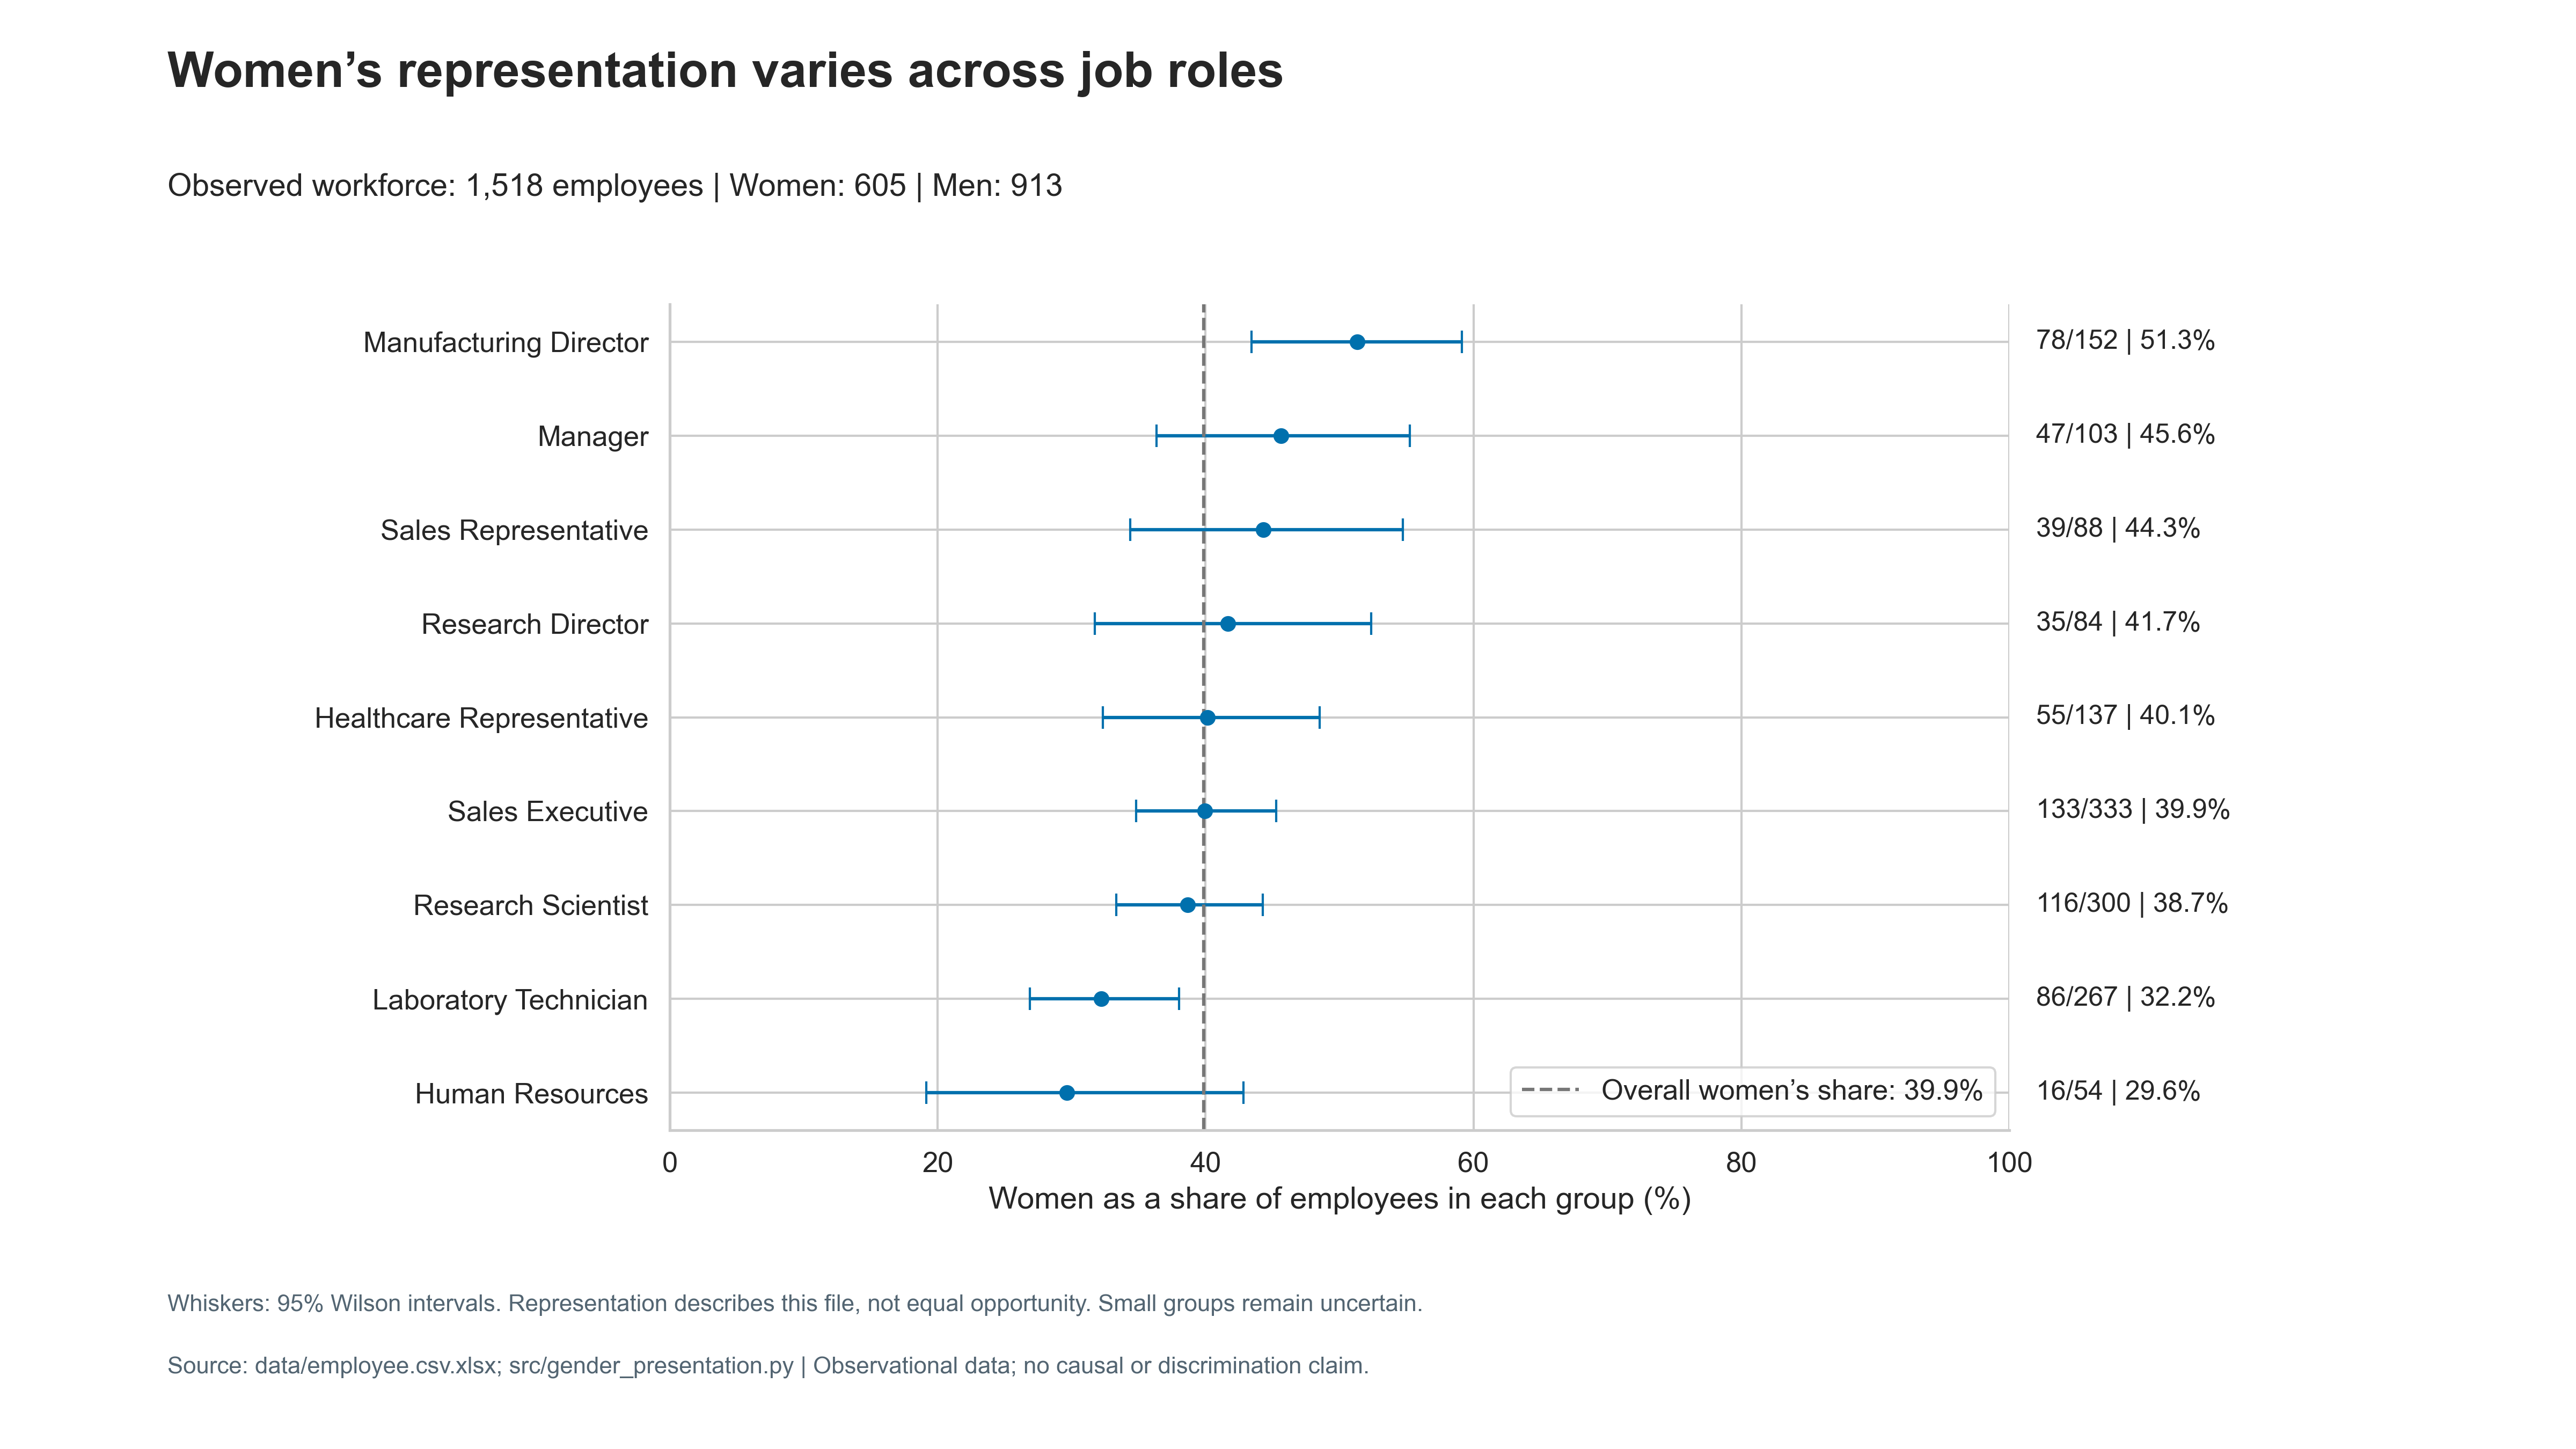

In [9]:
chart(state, 8)

## 09 — Context / appendix

La comparaison à niveau identique ne contrôle pas encore le métier, les heures ou l’expérience. Les effectifs de chaque boîte sont indiqués.

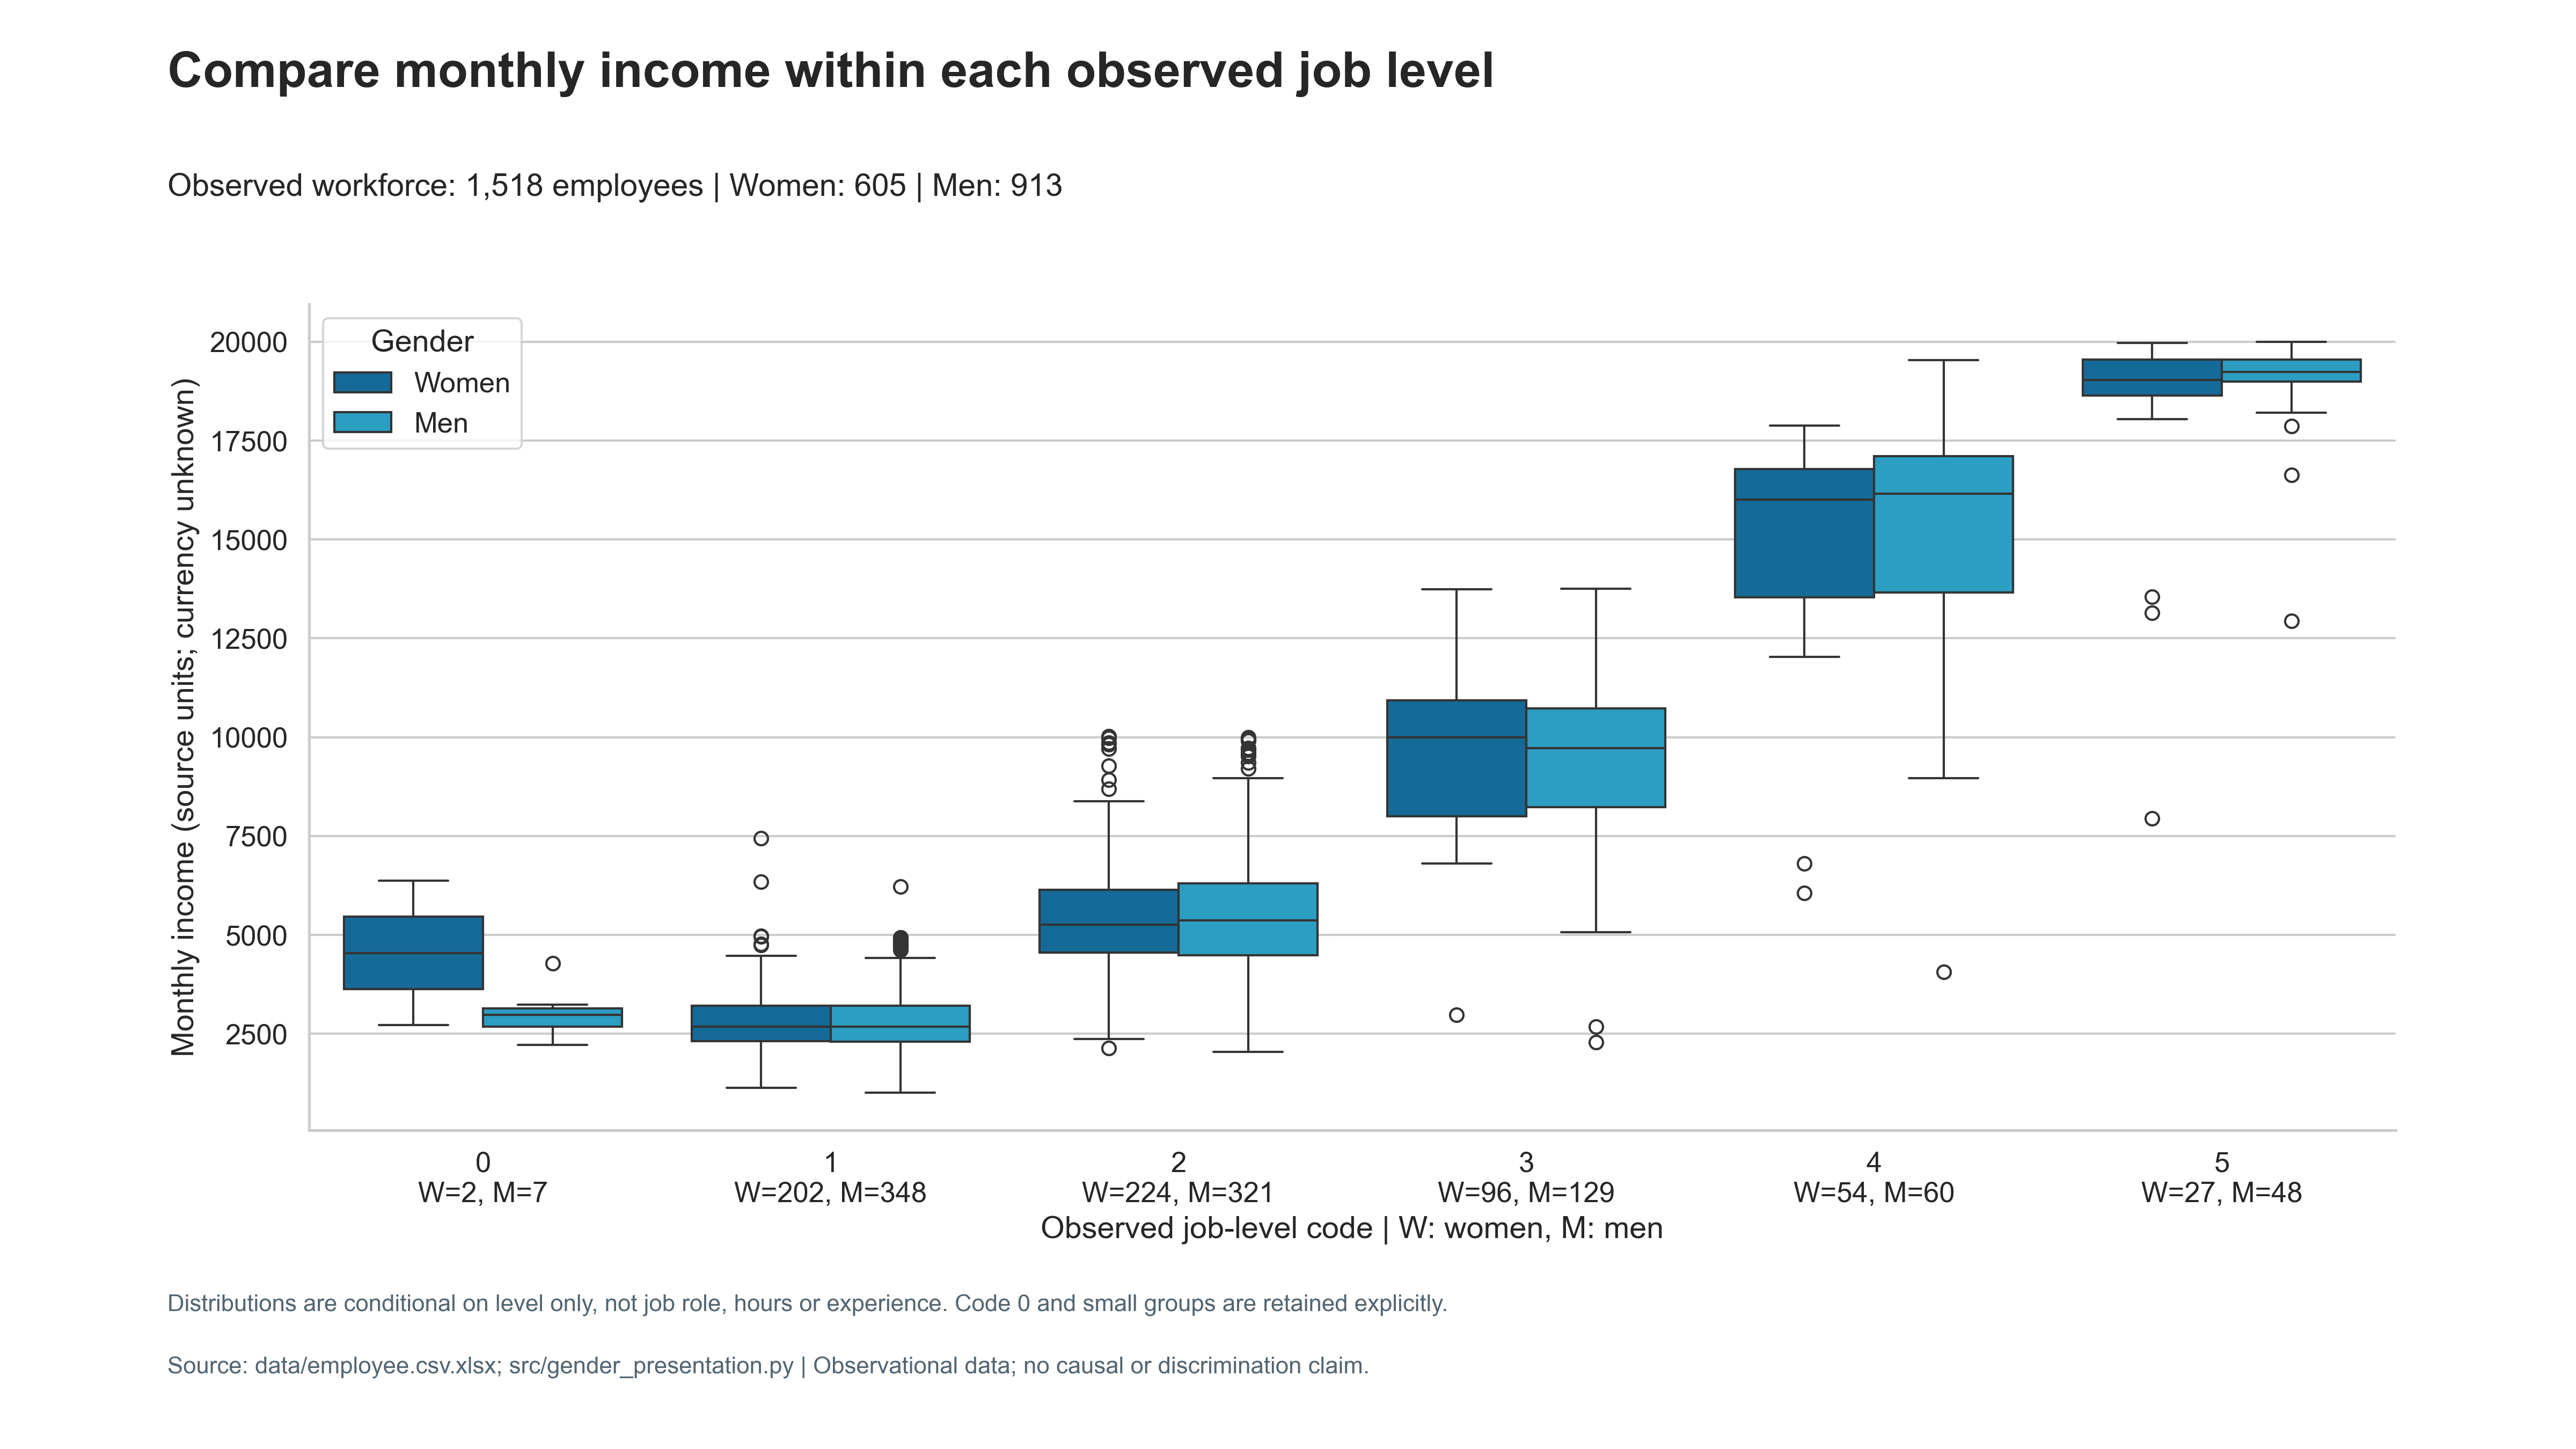

In [10]:
chart(state, 9)

## 10 — CORE presentation chart

**CORE.** Trois comparaisons distinctes : base complète brute, strates communes brutes, puis mêmes strates standardisées. Seuil : au moins 5 femmes et 5 hommes par métier/niveau. Barres : 500 bootstraps descriptifs ; poids des strates fixes pour la standardisation. Aucun ajustement complet de rémunération.

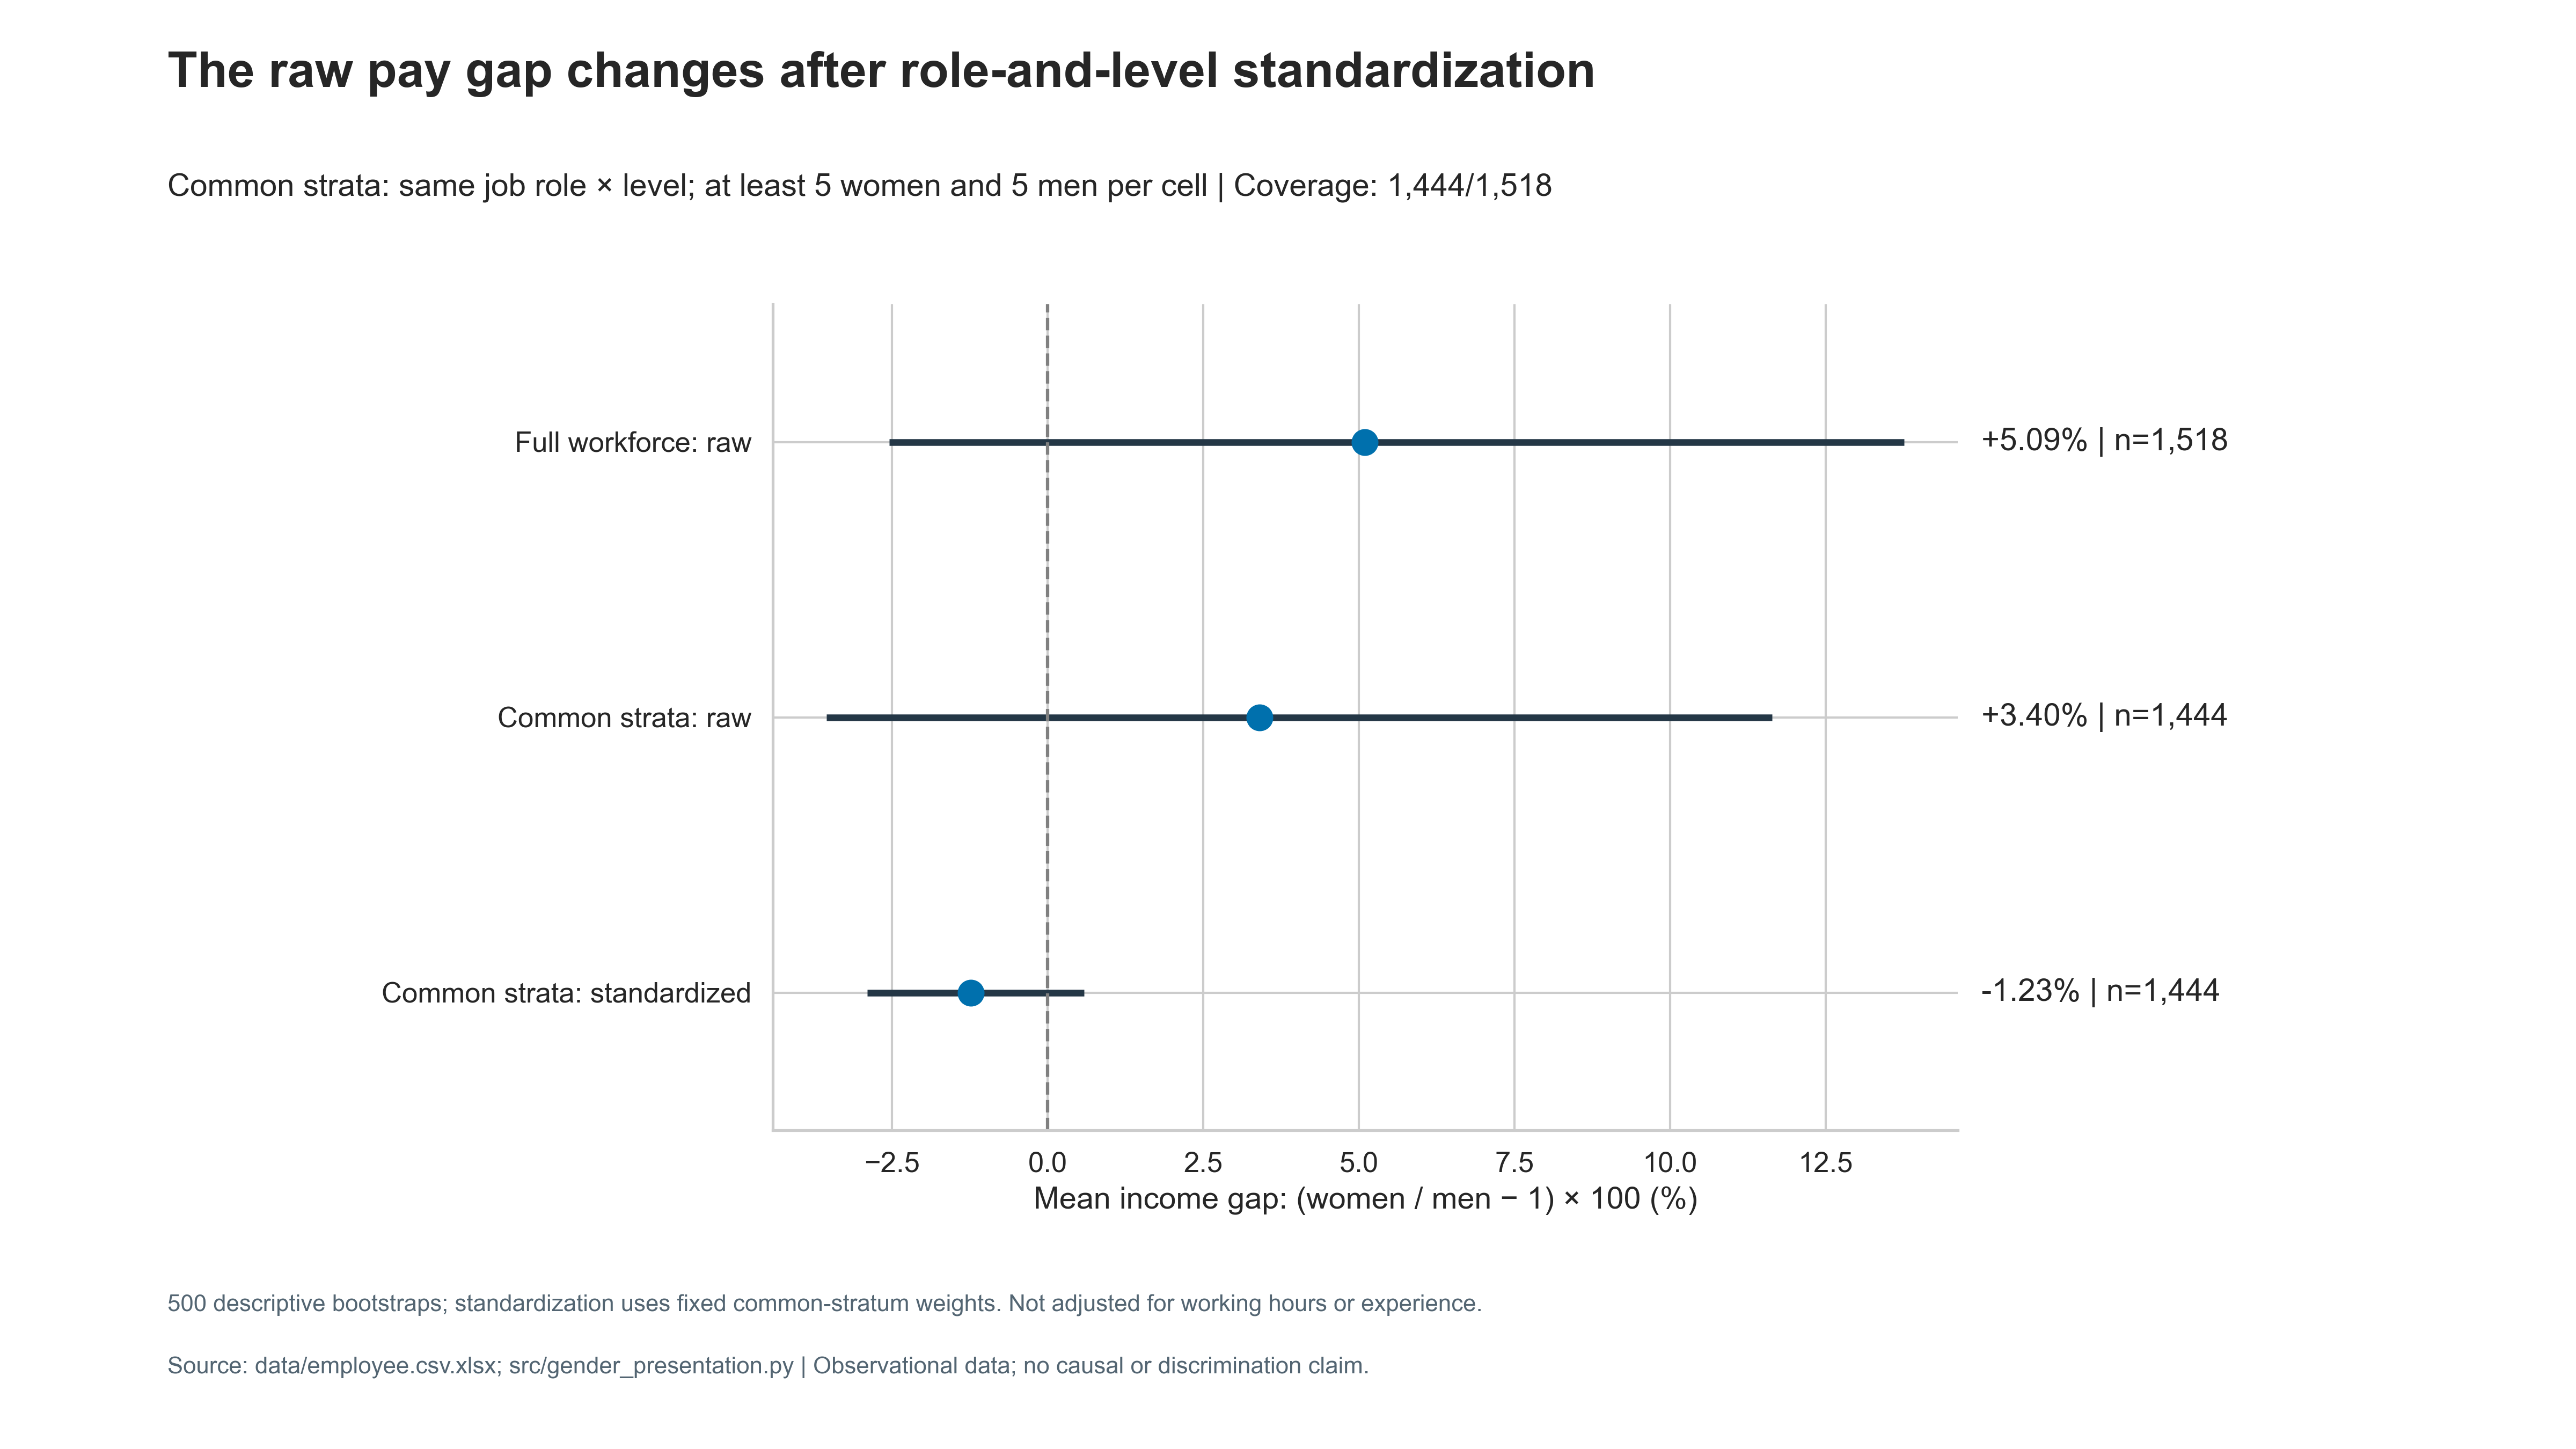

In [11]:
chart(state, 10)

## 11 — CORE presentation chart

**CORE.** Écarts de moyenne femmes/hommes par métier et niveau. Cellules masquées si un genre manque ou si un groupe compte moins de 5 salariés. Pas d’IC par cellule ni de test de discrimination.

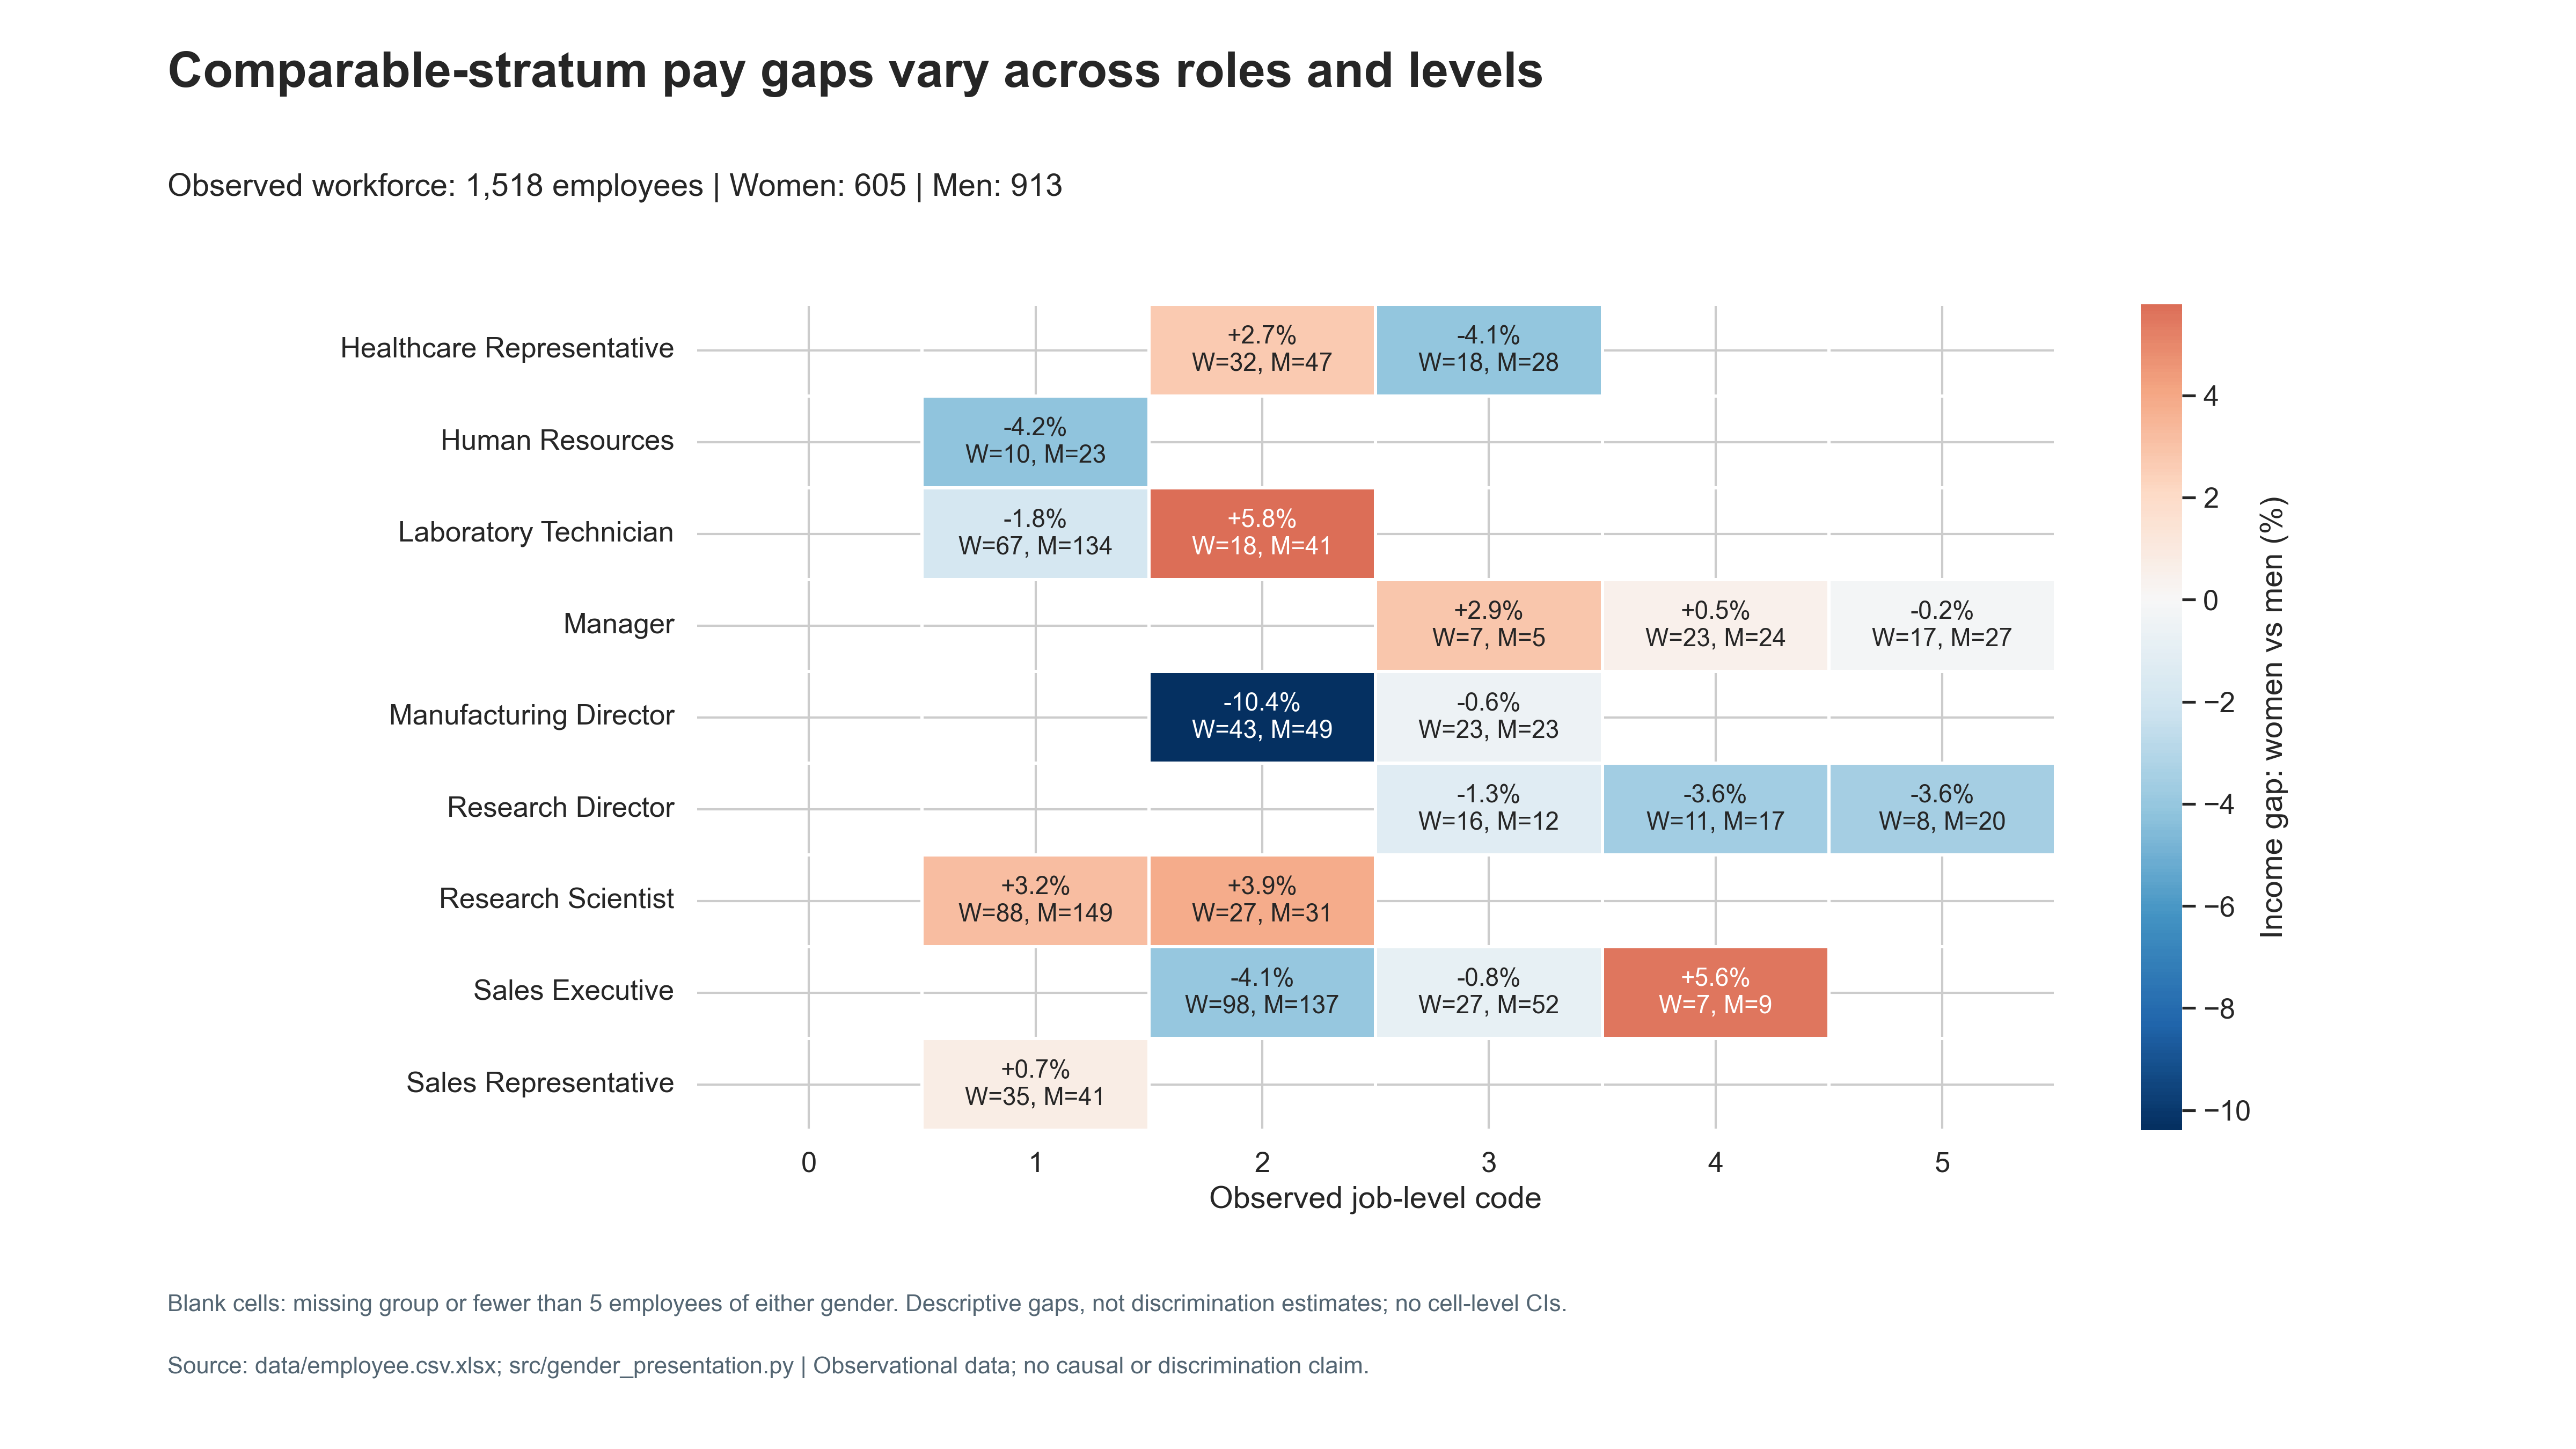

In [12]:
chart(state, 11)

## 12 — CORE presentation chart

**CORE.** Comparaison des départs selon les heures supplémentaires au sein de chaque genre. Étiquettes = départs/effectifs, IC Wilson. Pas d’interaction causale ni de comparaison à métier identique.

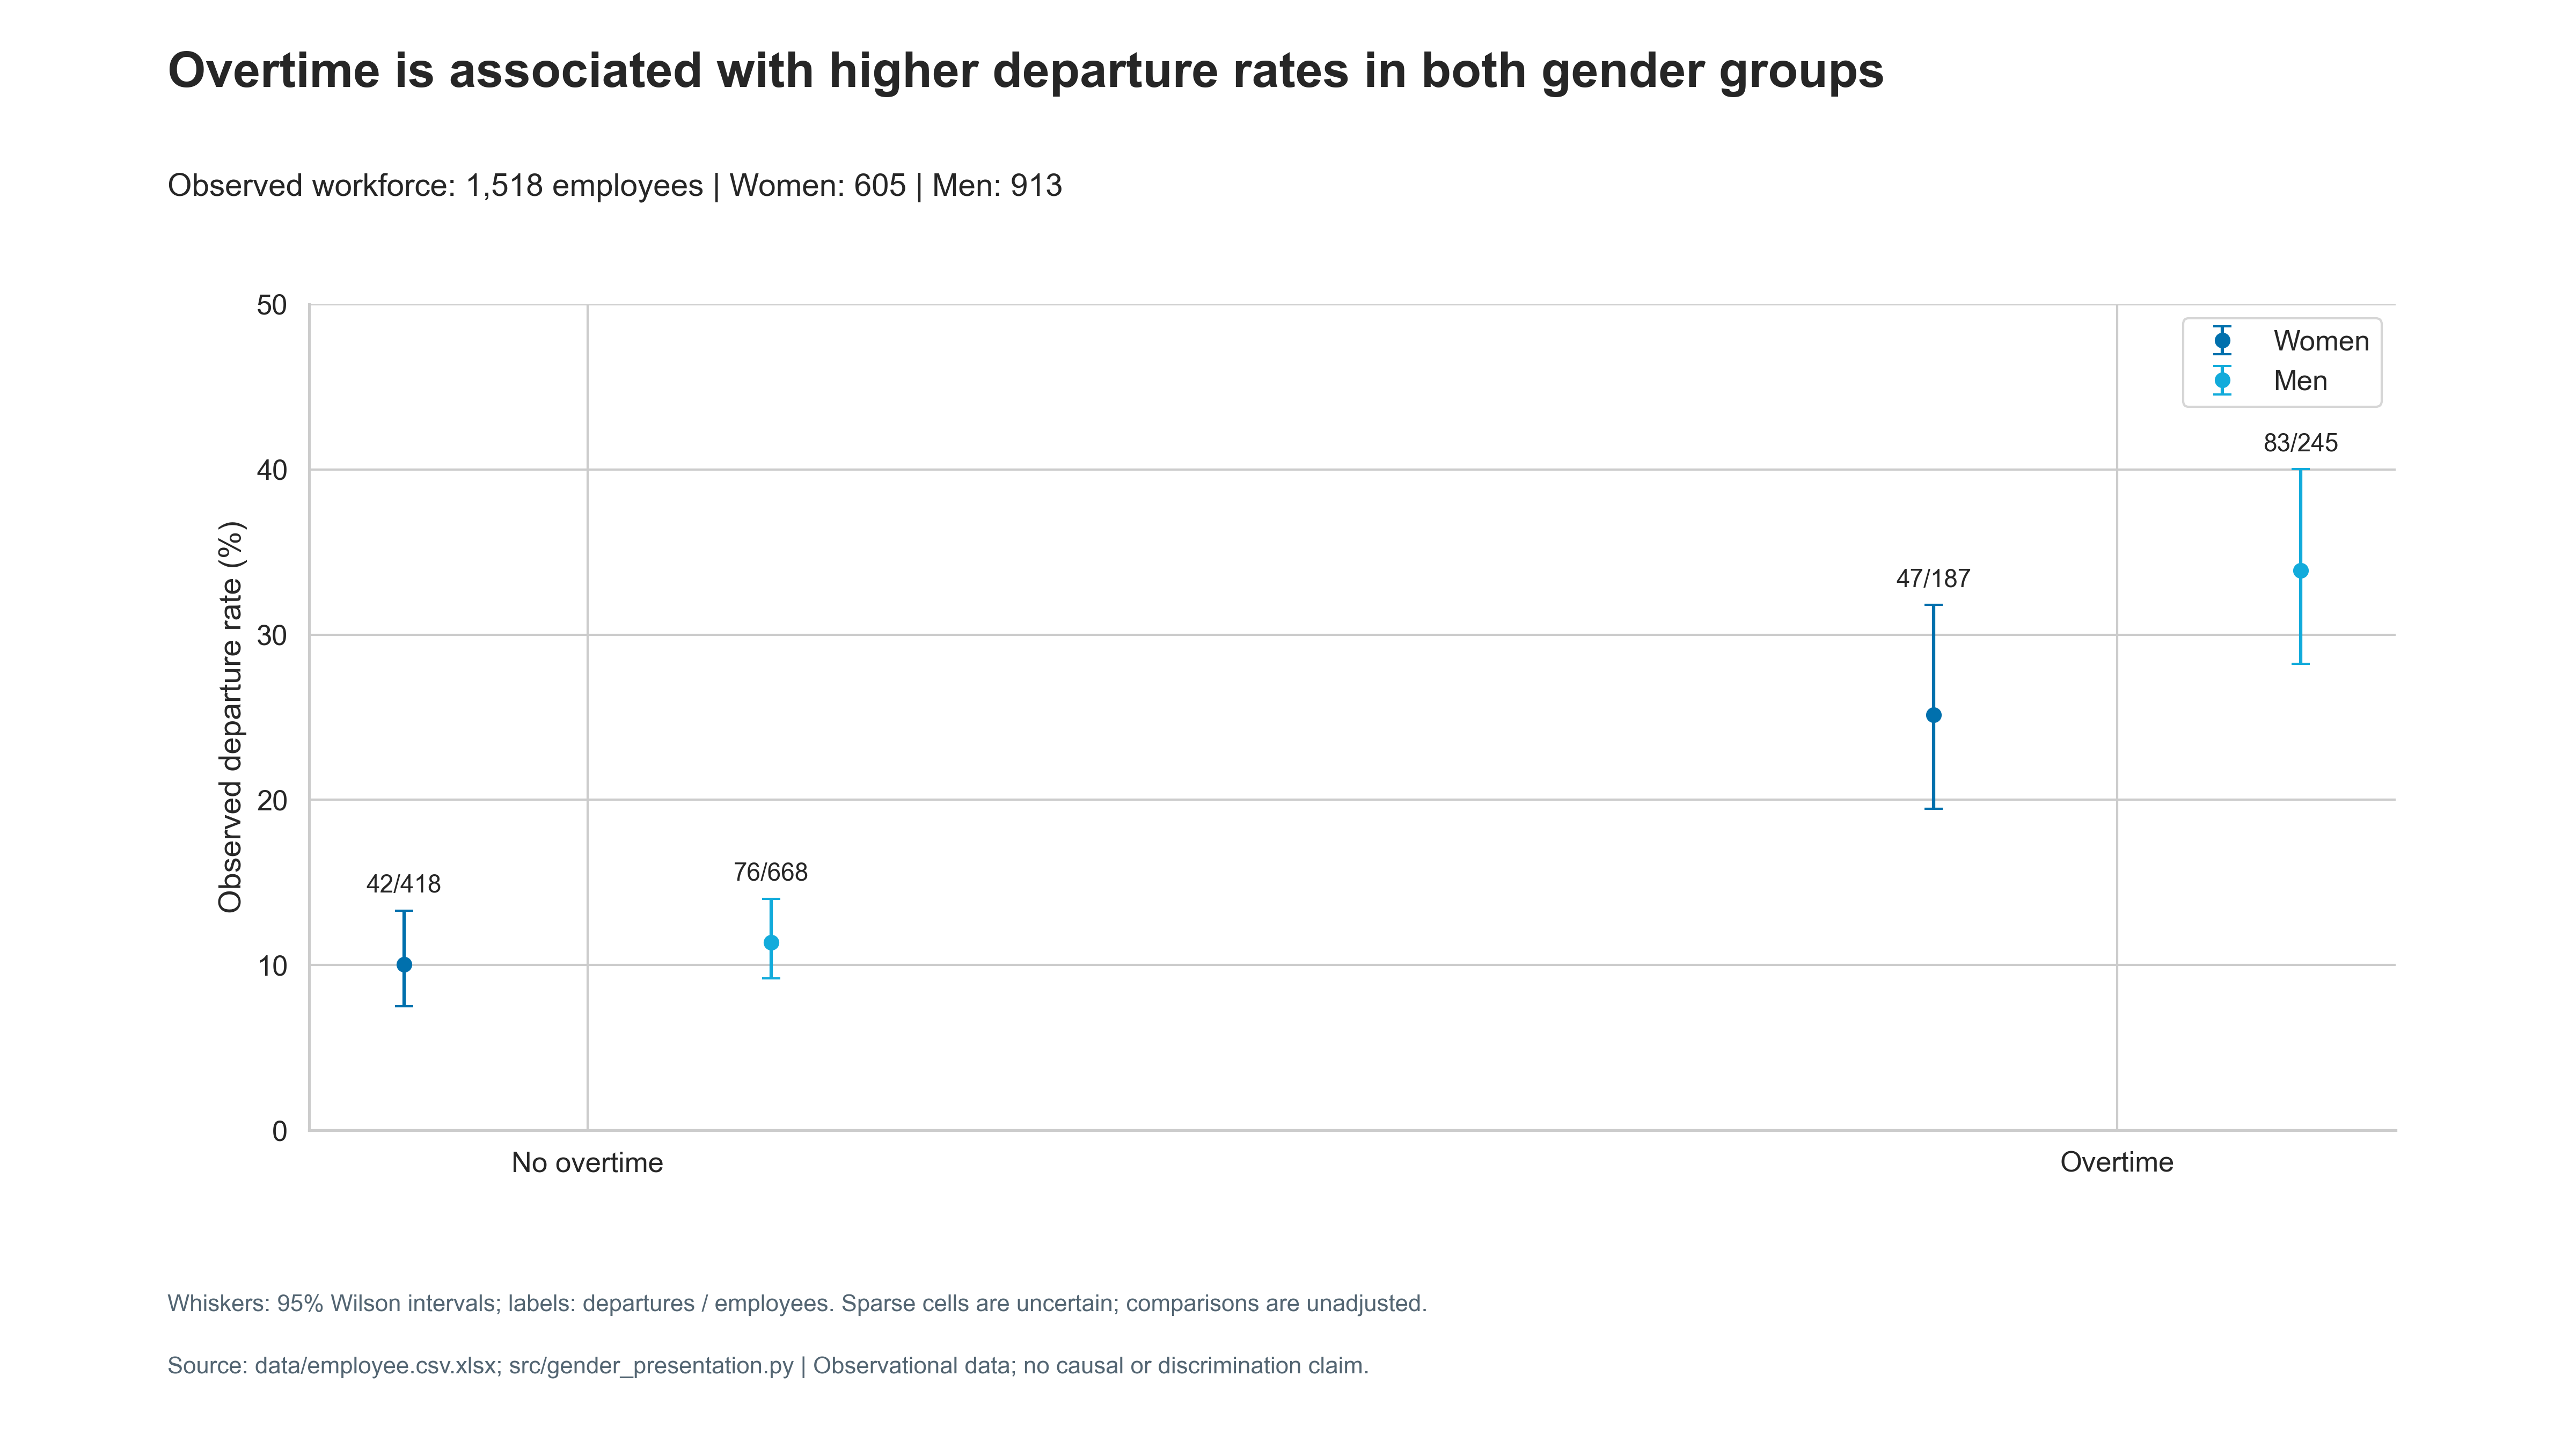

In [13]:
chart(state, 12)

## 13 — Context / appendix

Annexe : les cellules de niveaux rares sont affichées avec des IC larges, jamais utilisées comme conclusion ferme.

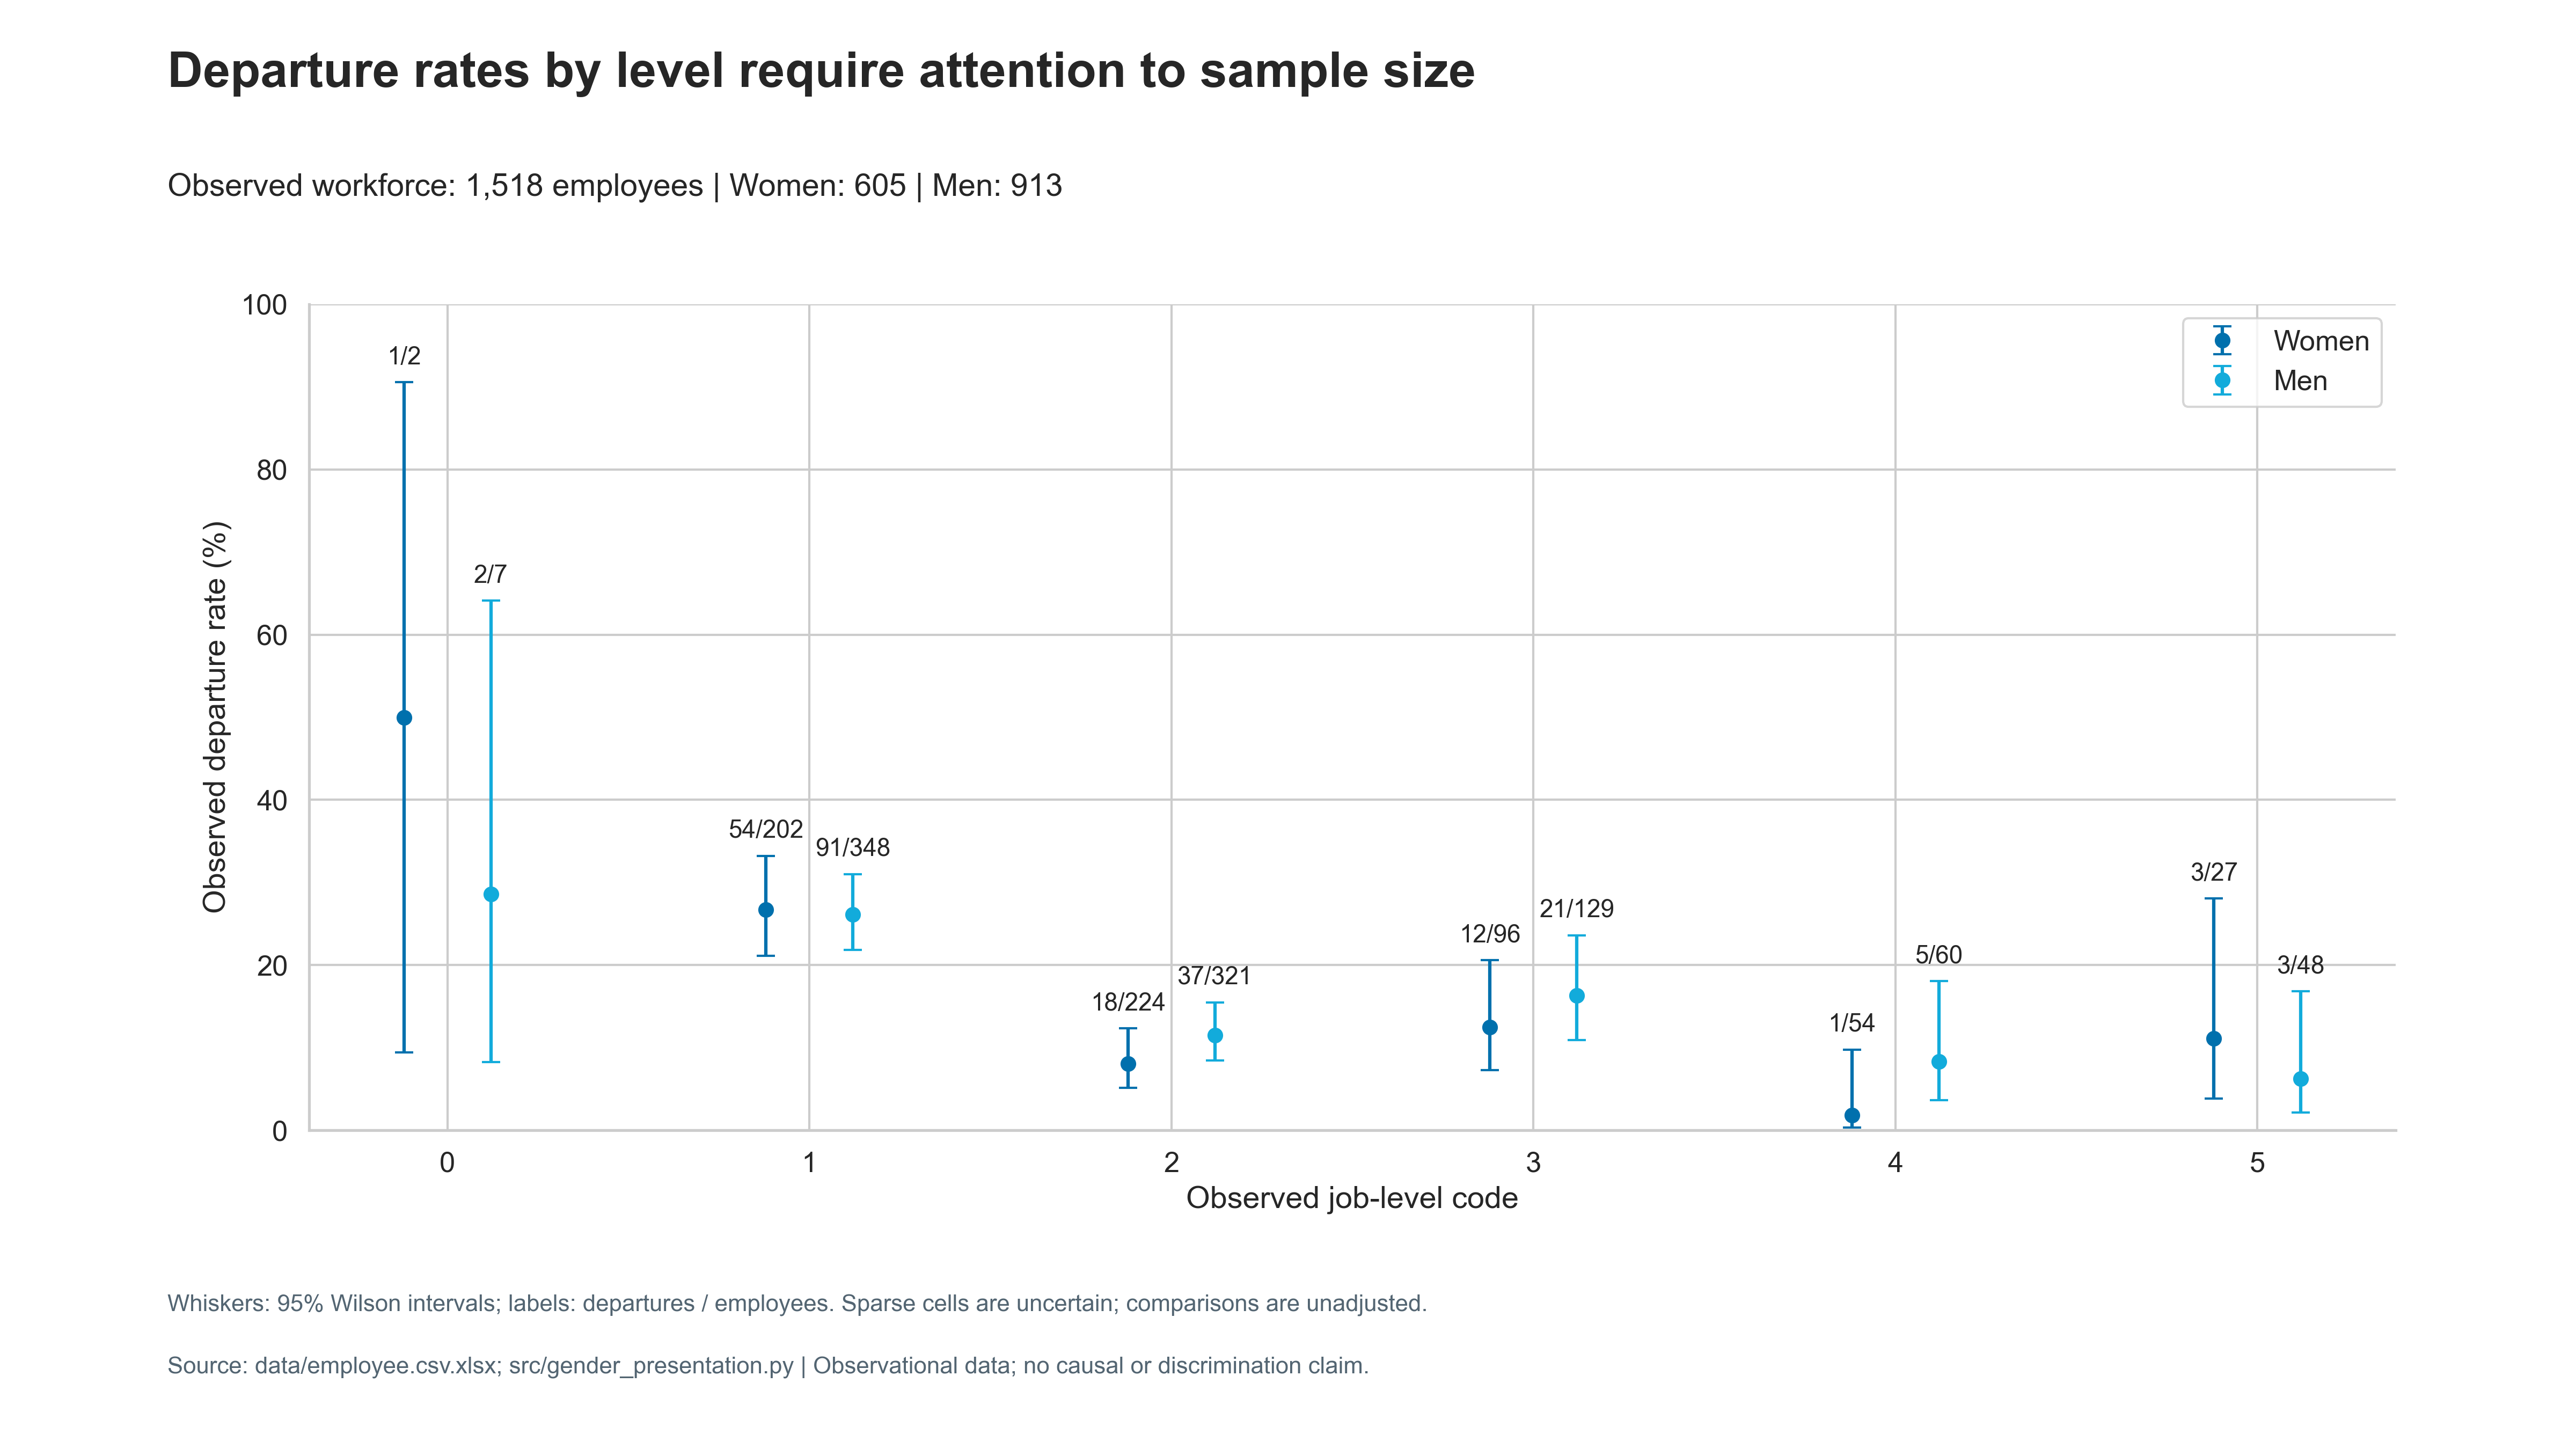

In [14]:
chart(state, 13)

## 14 — Context / appendix

Augmentations enregistrées, période inconnue. Ce n’est ni une mesure d’éligibilité ni une probabilité d’obtenir une augmentation.

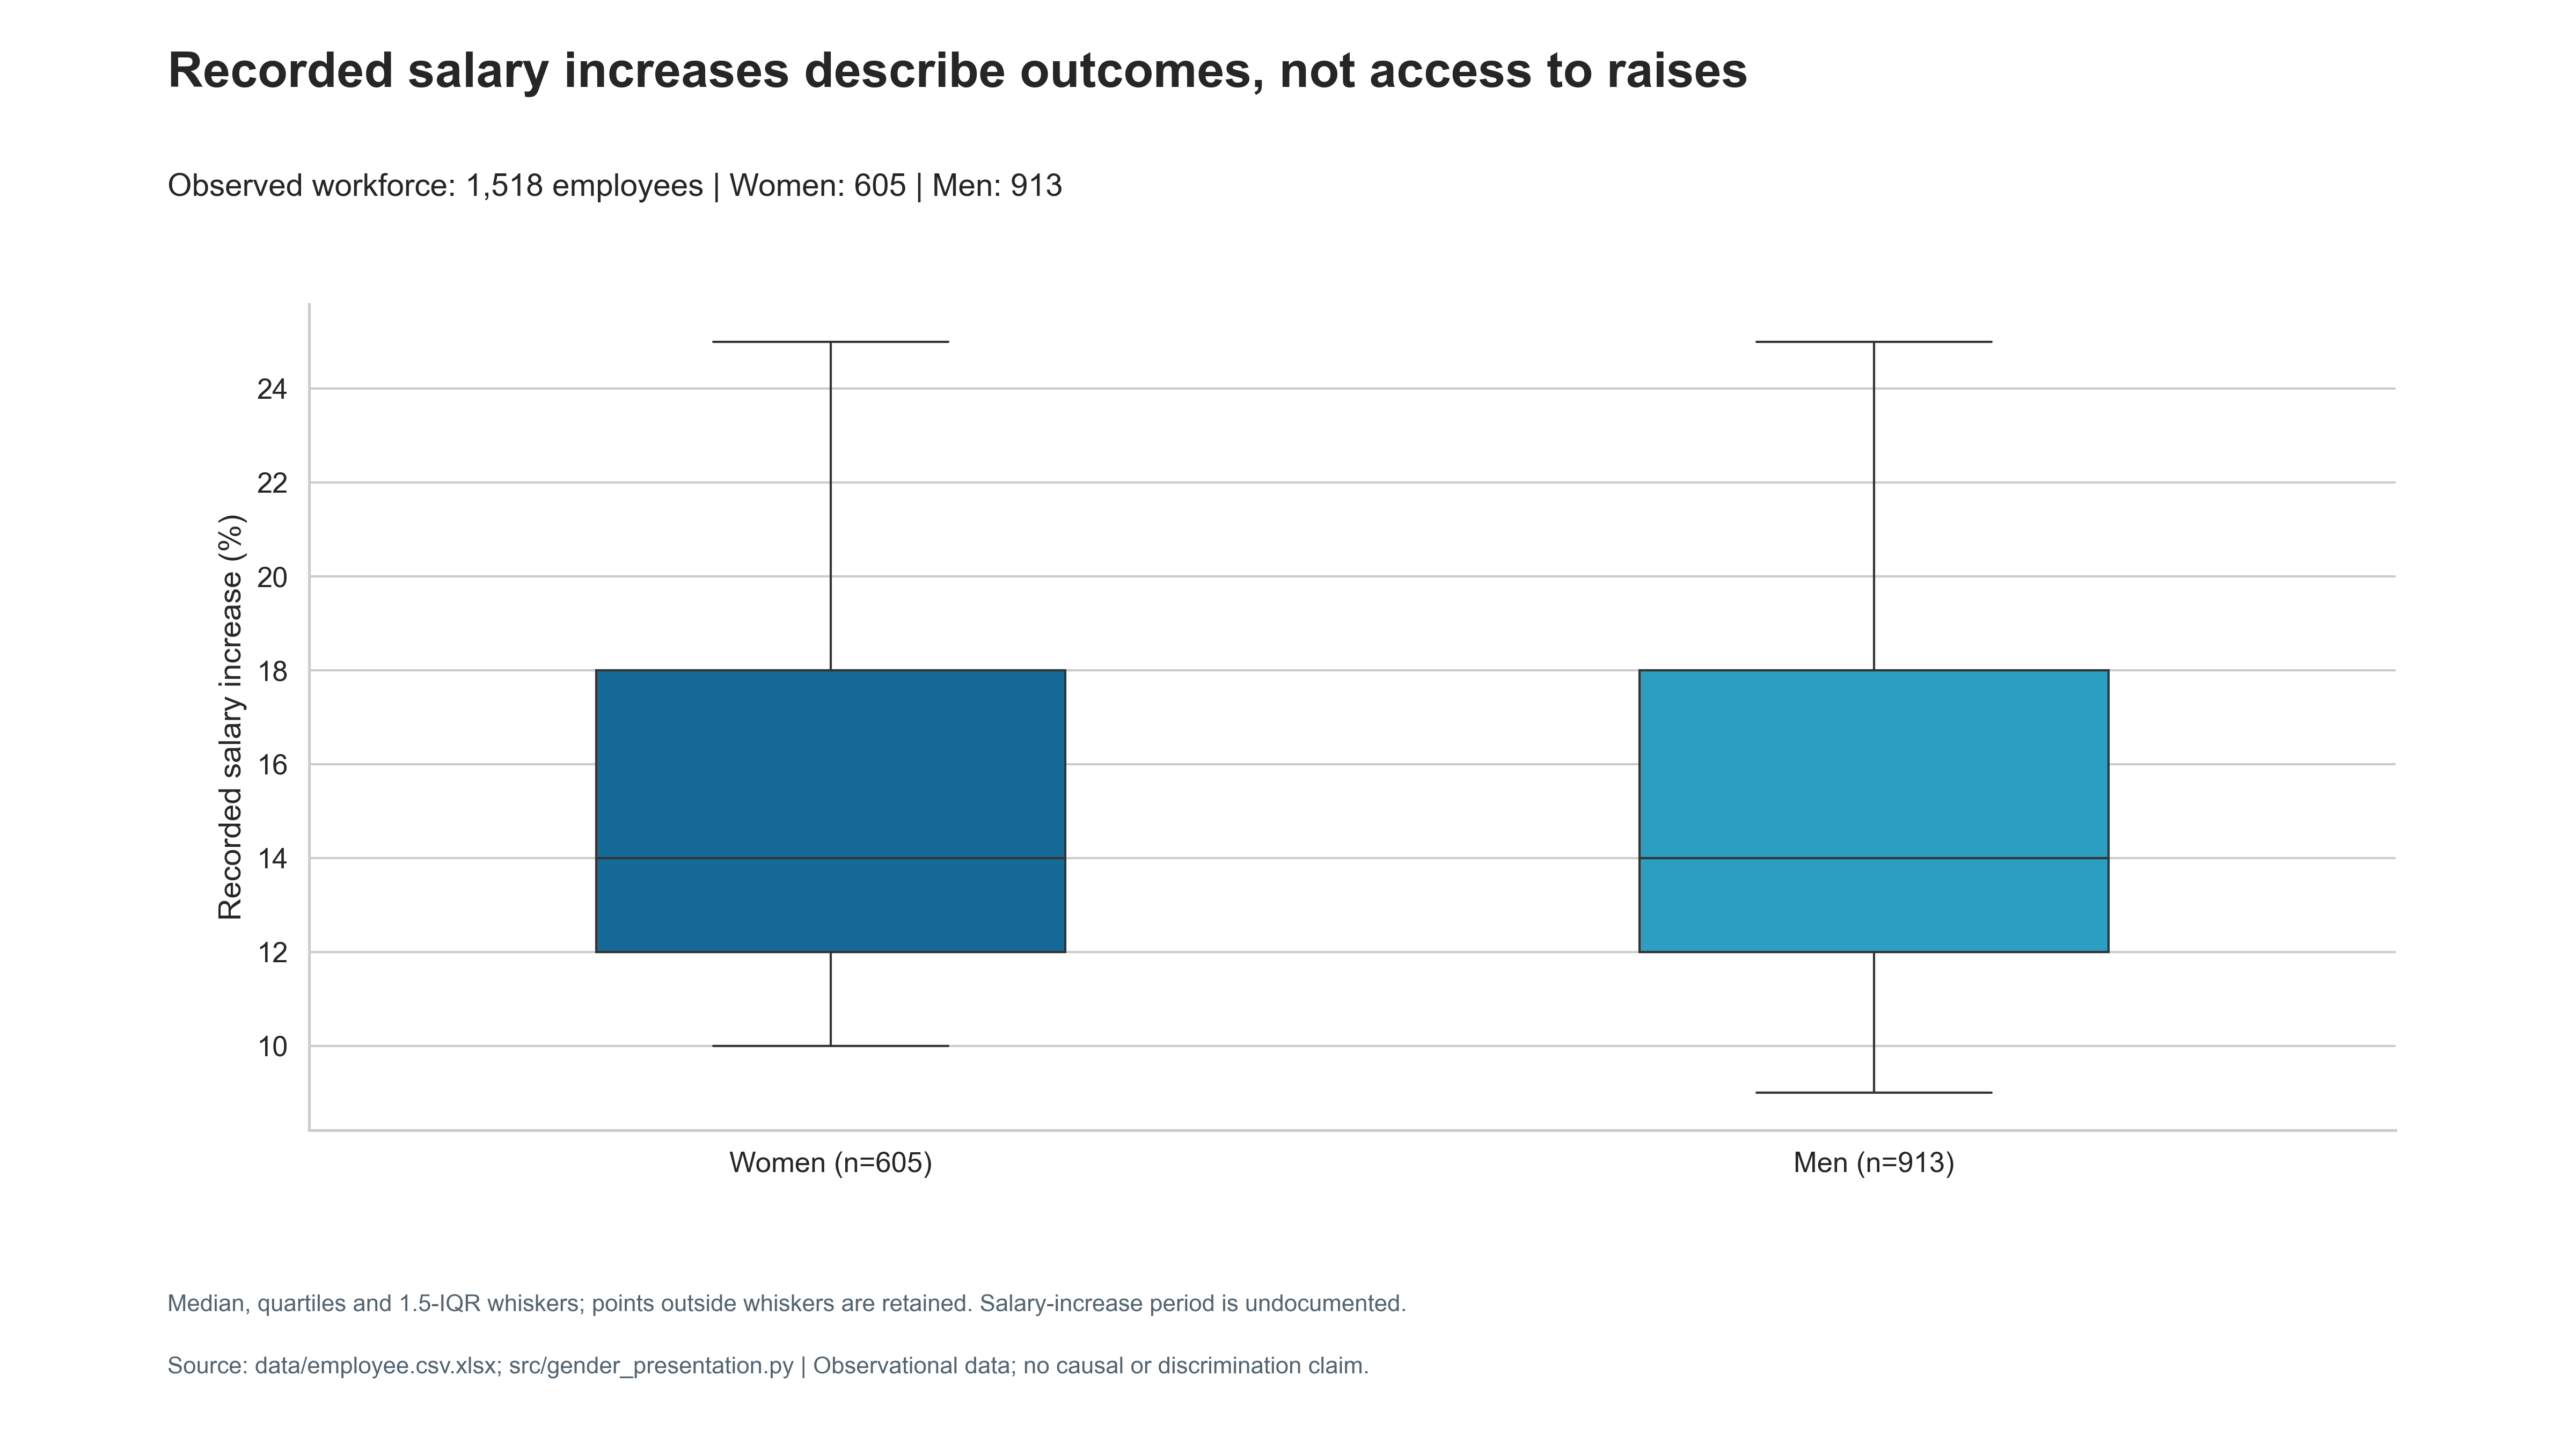

In [15]:
chart(state, 14)

## 15 — Context / appendix

Ancienneté, temps dans le rôle et délai depuis la promotion : indicateurs de calendrier, pas taux de promotion. Incohérences d’ancienneté conservées selon le protocole.

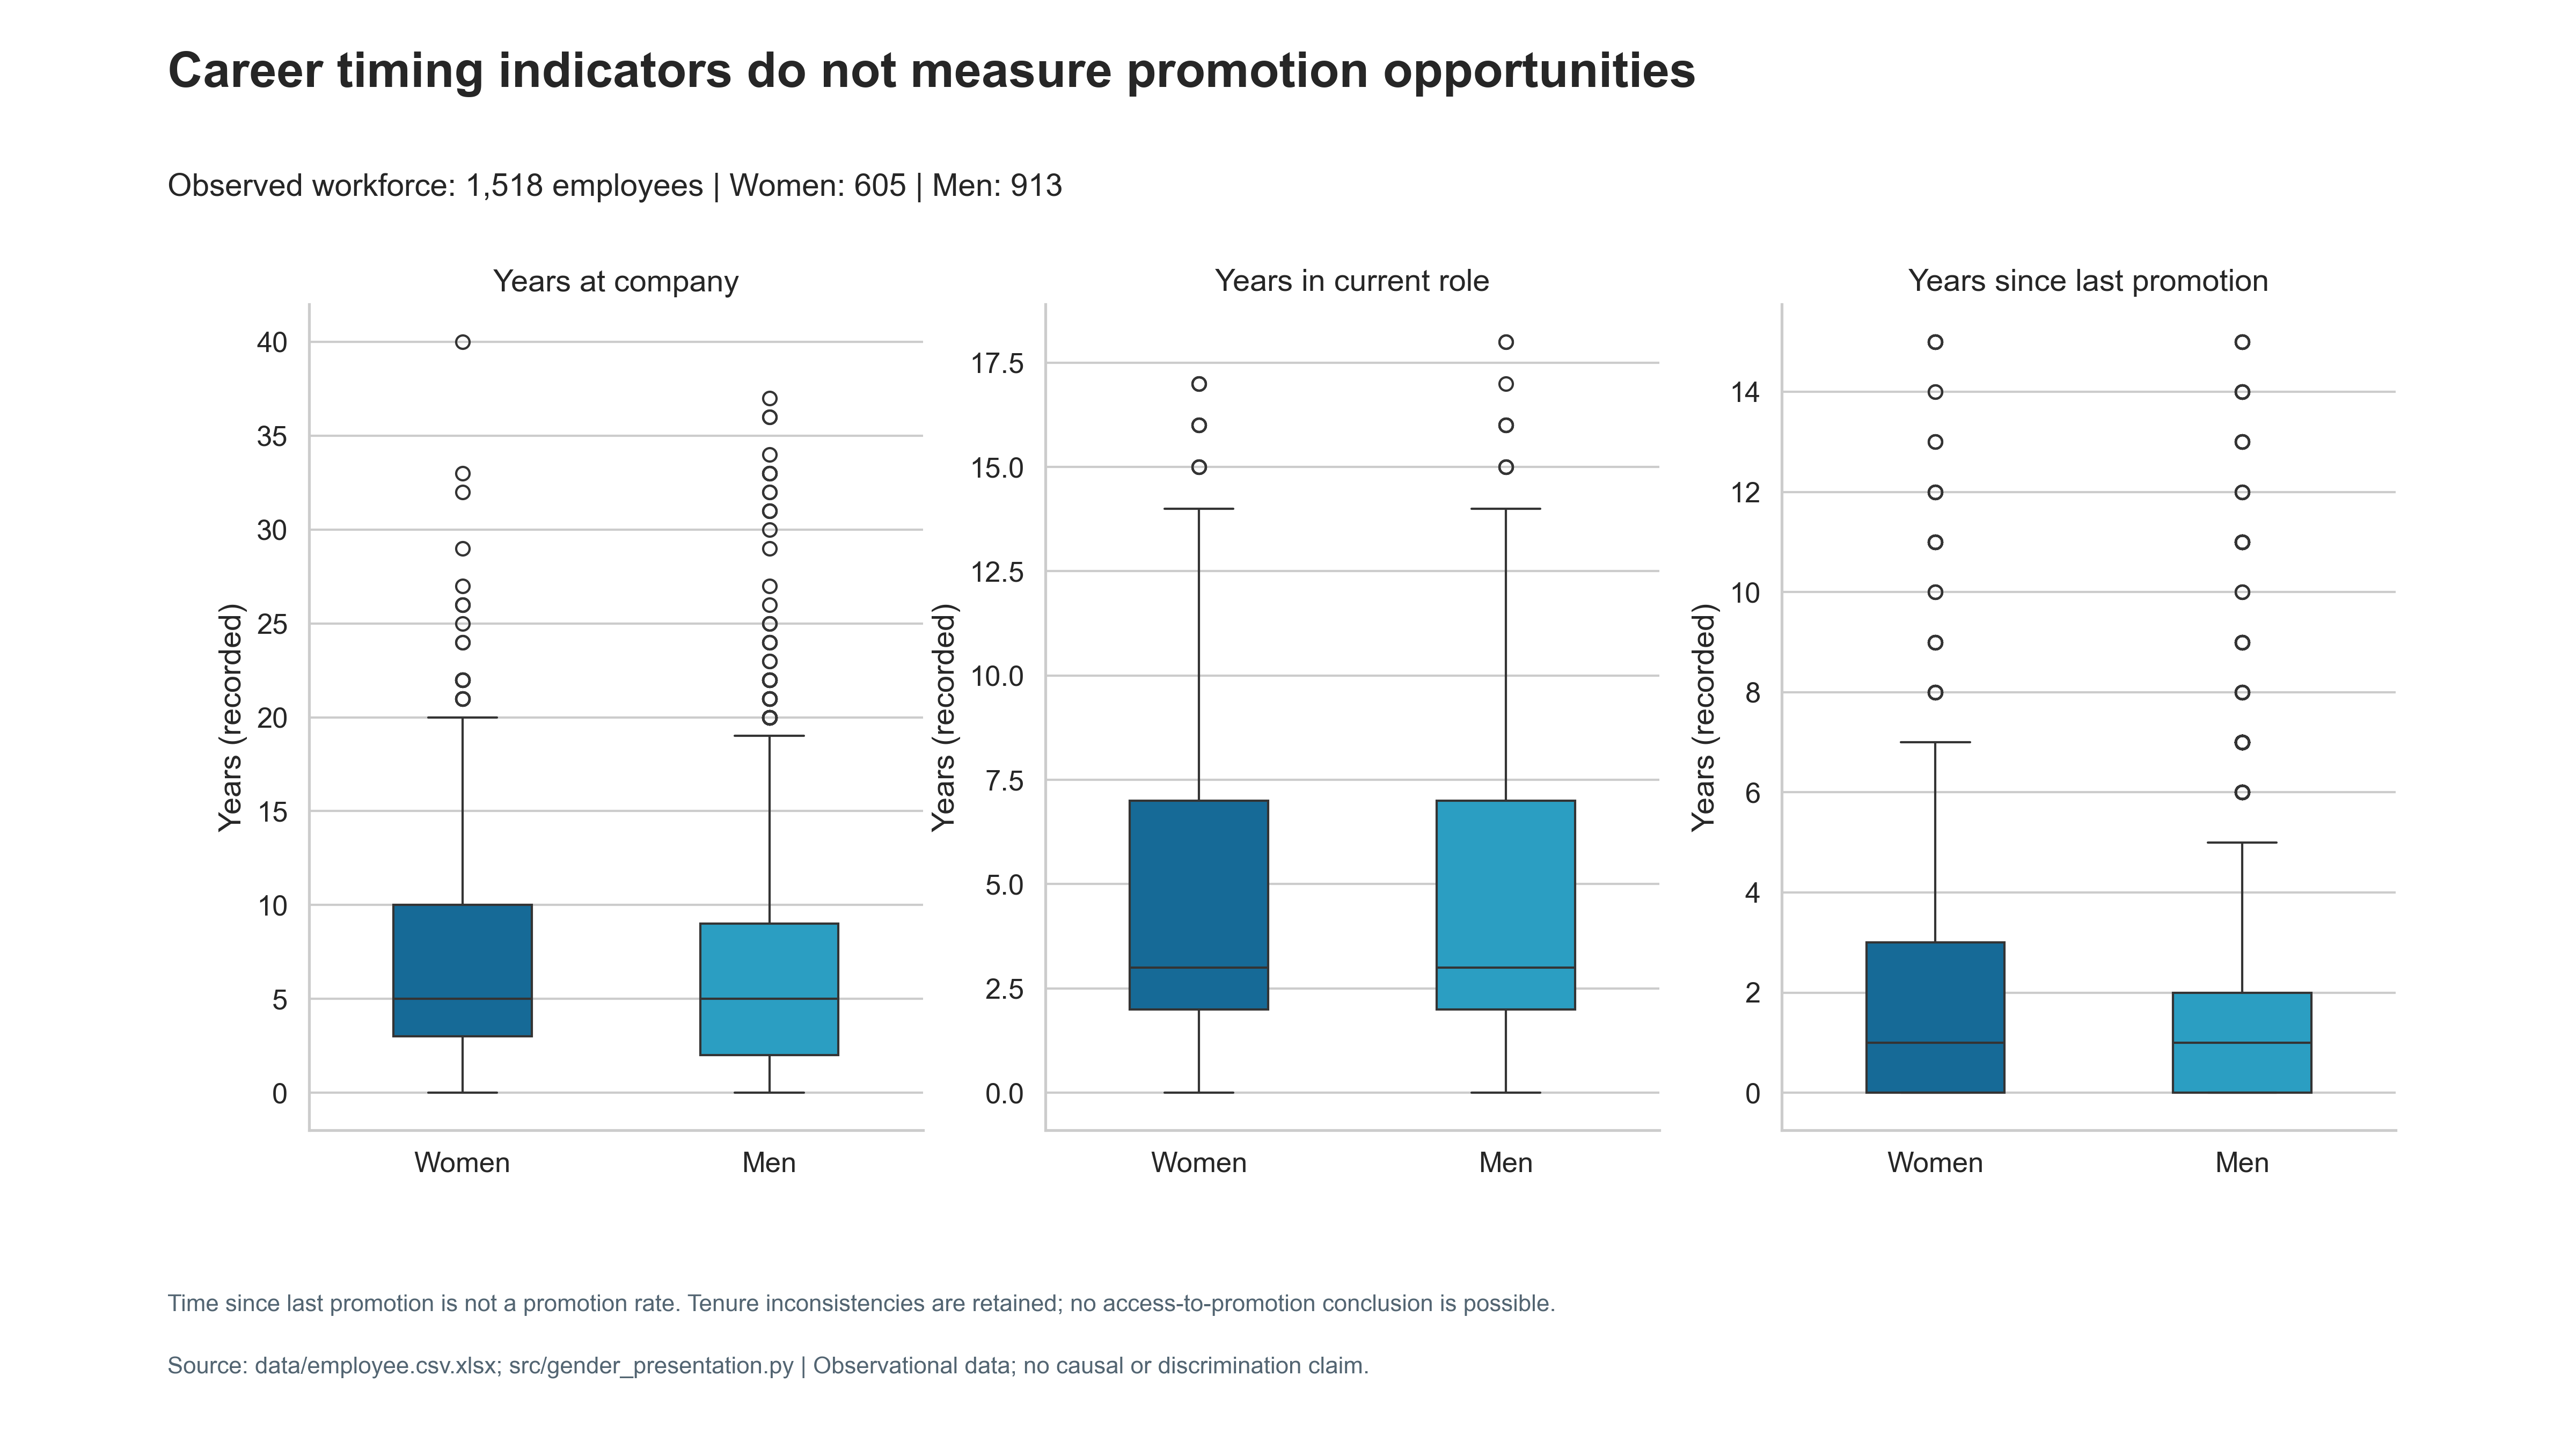

In [16]:
chart(state, 15)

## 16 — Context / appendix

Nombre de formations l’année précédente, tel que renseigné. Ni volume horaire, ni qualité, ni population éligible.

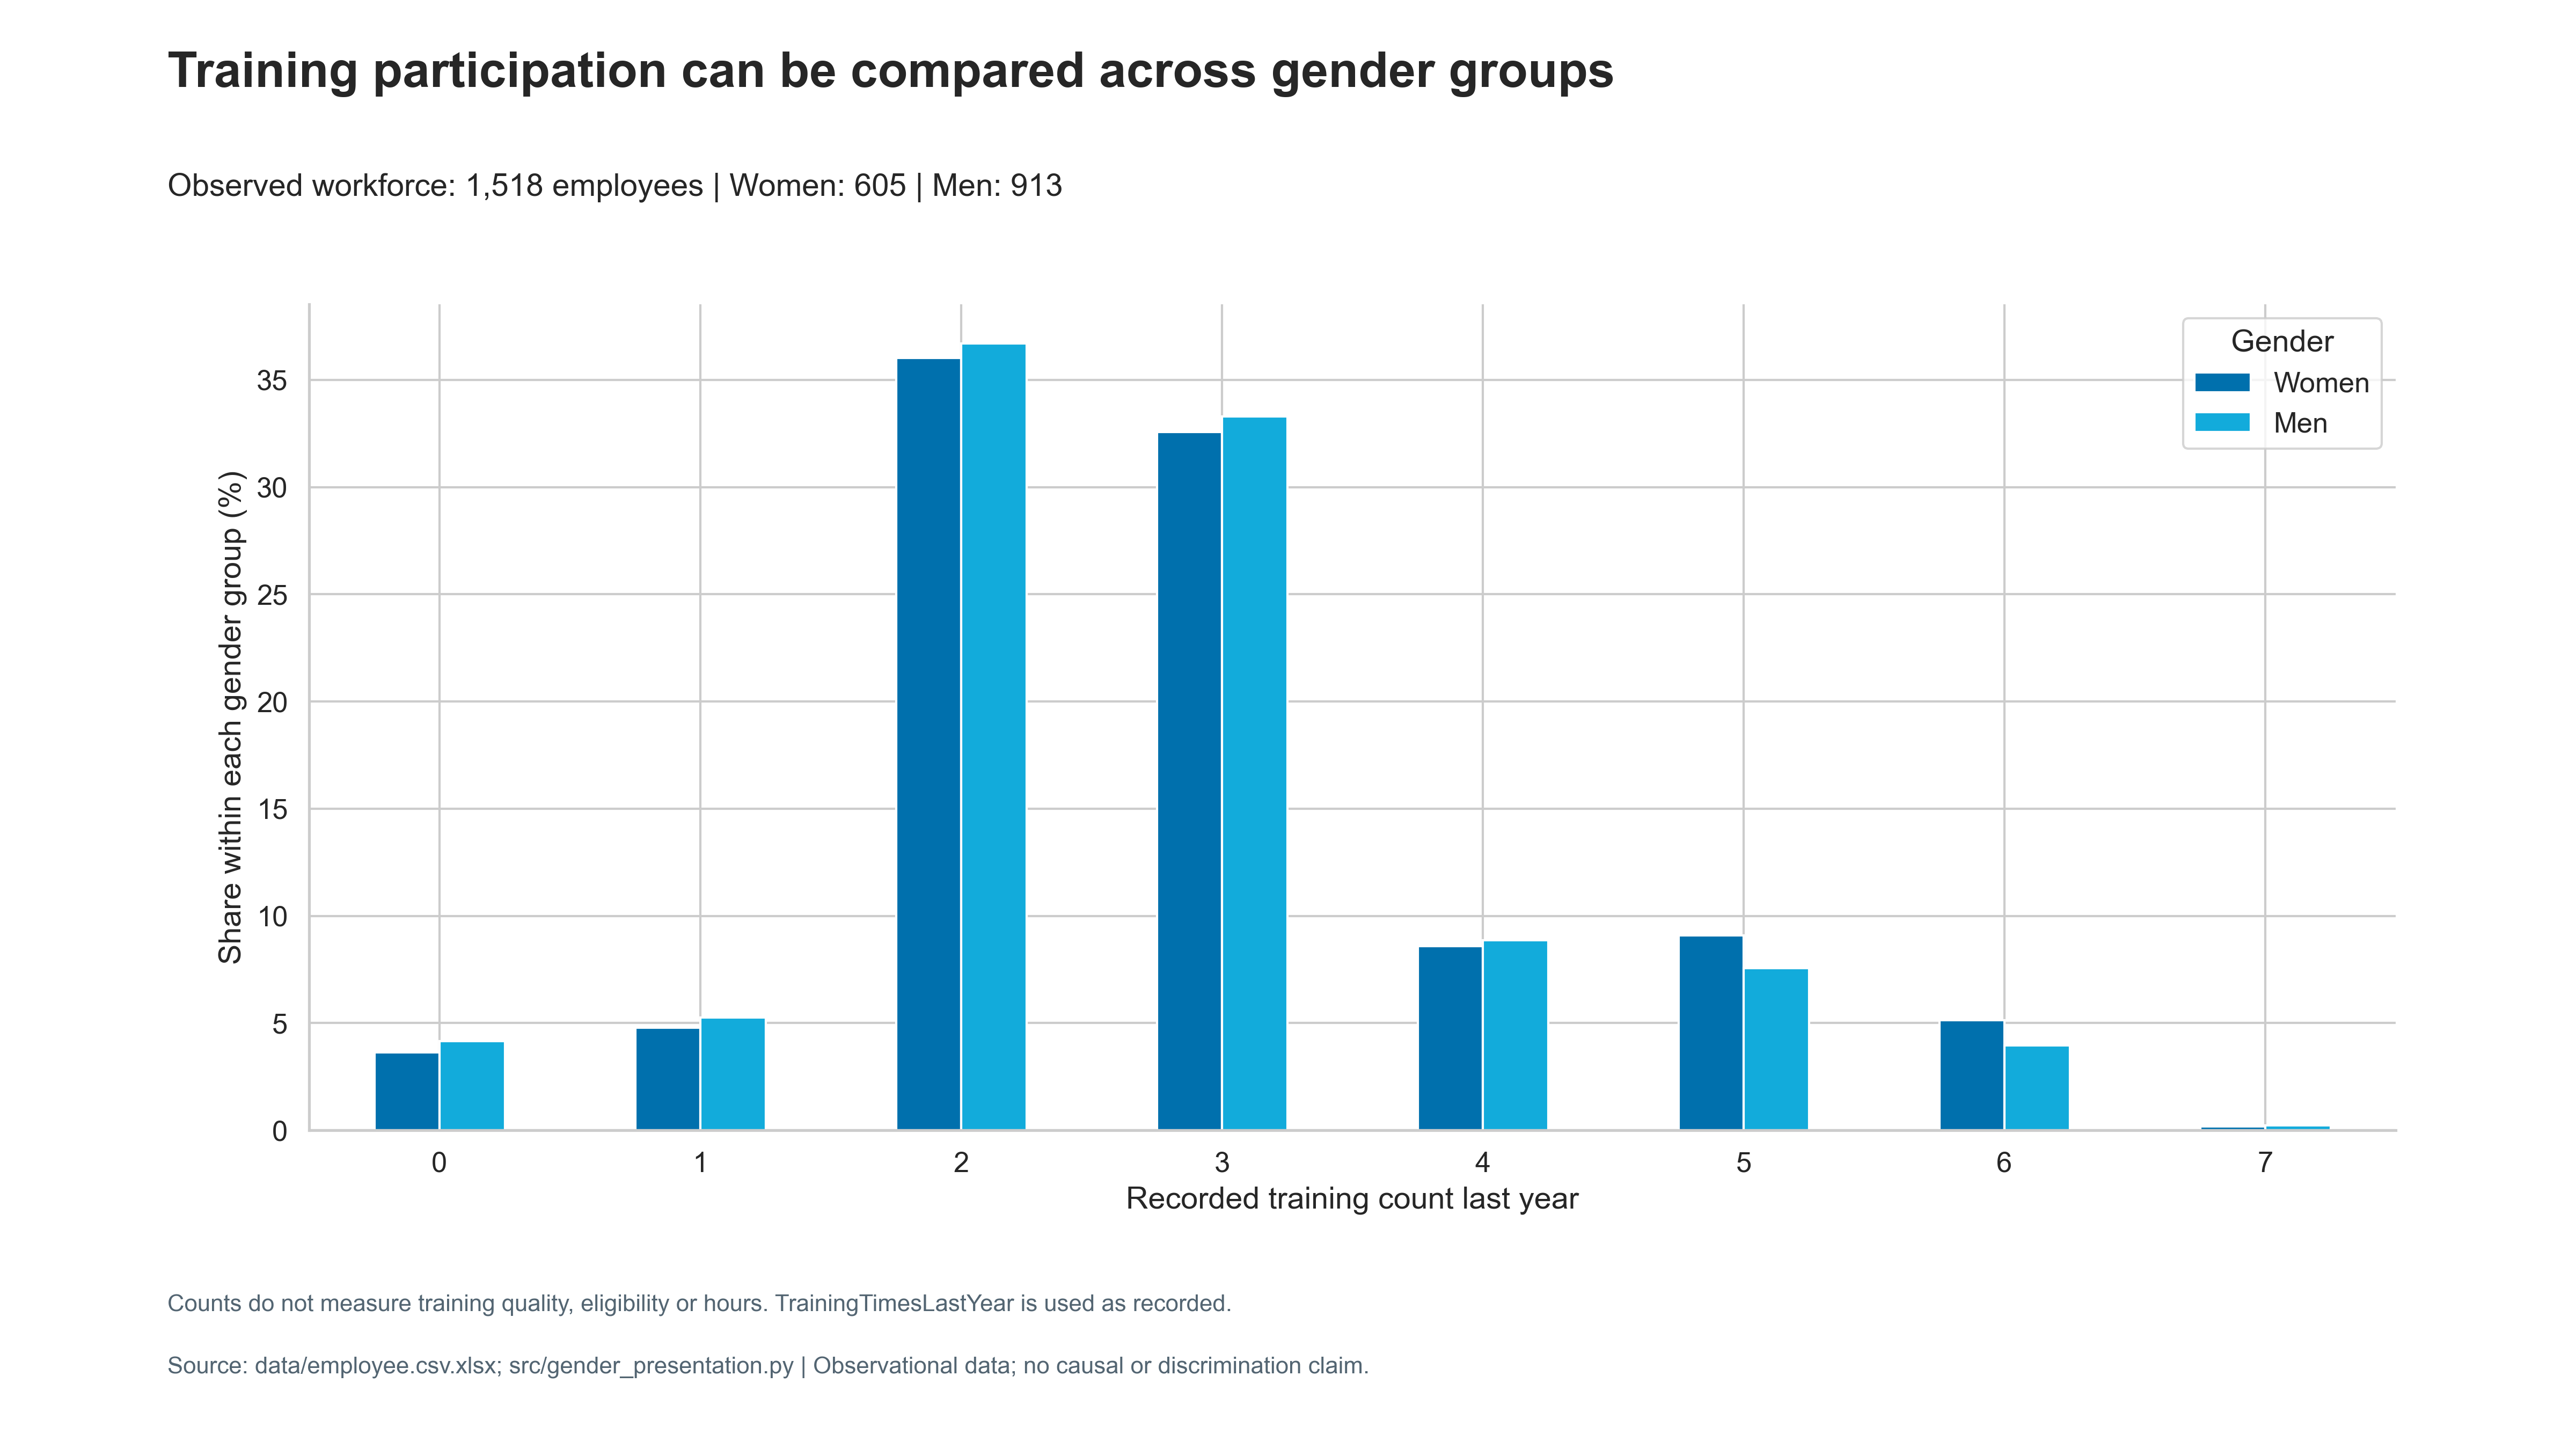

In [17]:
chart(state, 16)

## 17 — Context / appendix

Analyse de sensibilité aux seuils de 1, 5 et 10 salariés de chaque genre par strate. Les populations et les poids changent ; ces variations ne sont pas des IC.

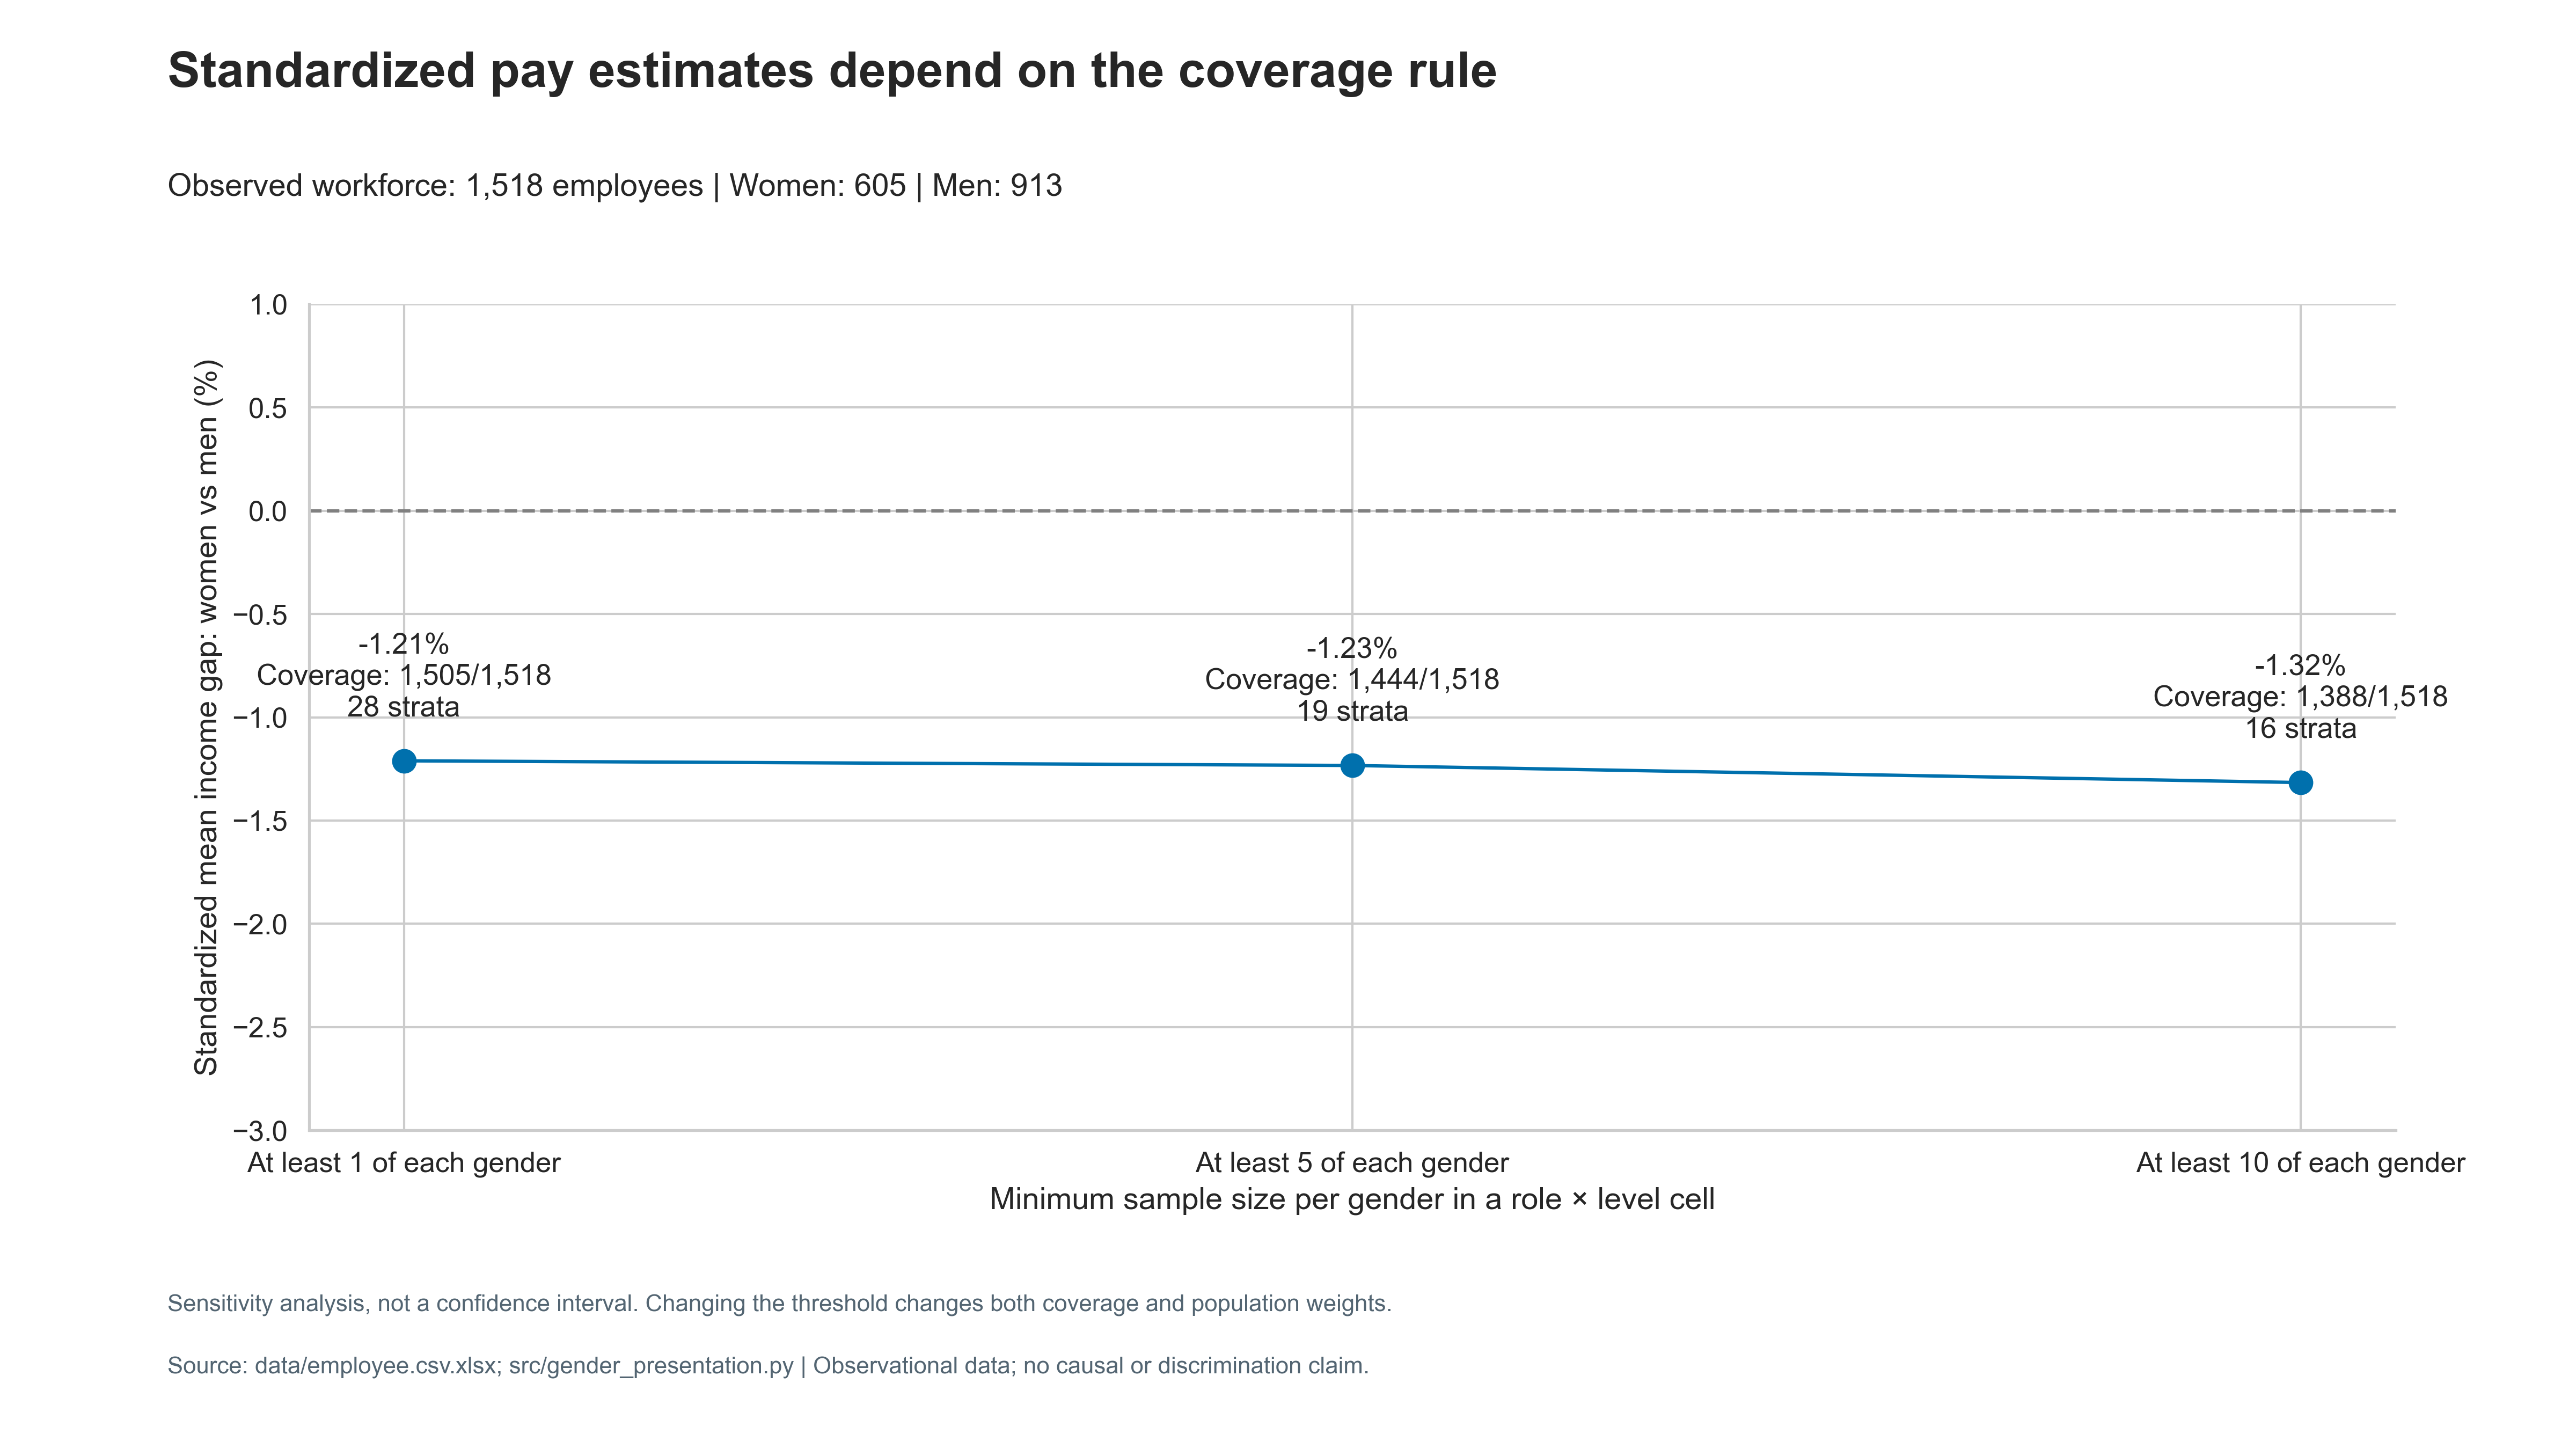

In [18]:
chart(state, 17)

## 18 — Context / appendix

Carte de représentation : part de femmes dans chaque métier/niveau. Cellules de moins de 10 personnes masquées ; ne pas confondre composition et accès aux promotions.

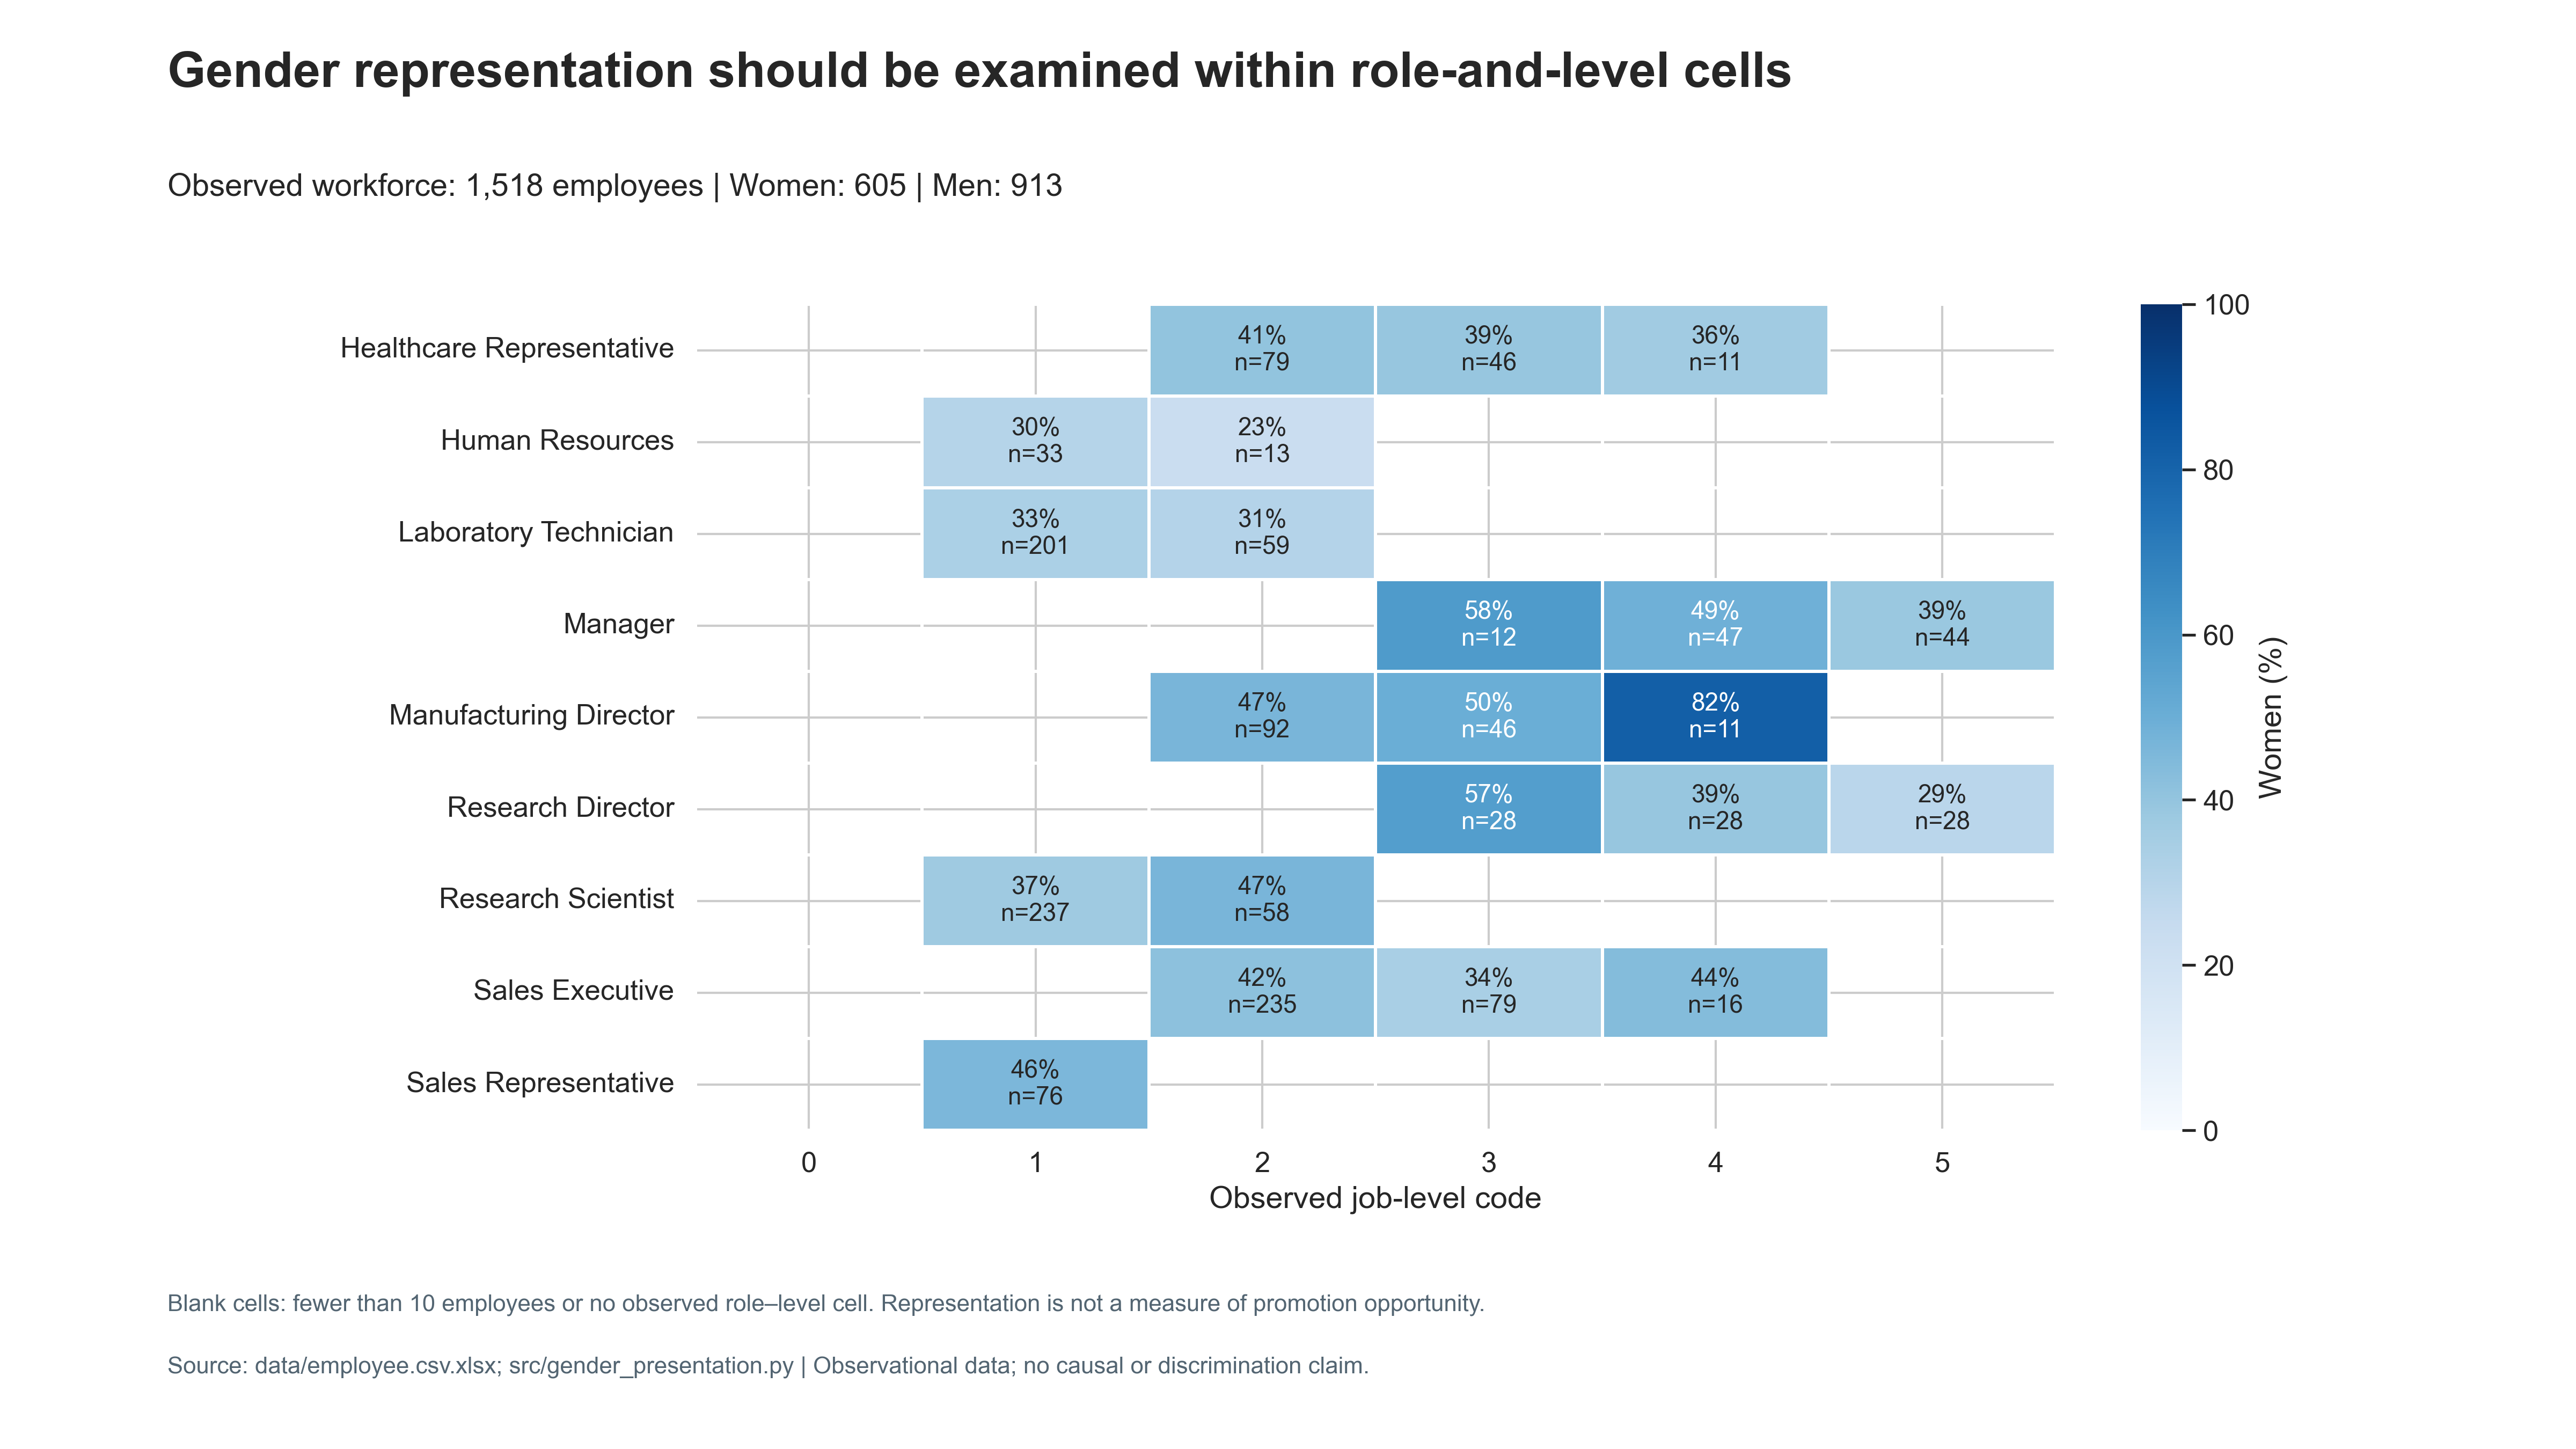

In [19]:
chart(state, 18)

## Sources, vérification et export

Les exports historiques de `outputs/tables/02_egalite_femmes_hommes/` sont conservés. Les nouvelles sources de graphiques, le catalogue et les métadonnées sont isolés dans `outputs/02_gender_presentation/`. Les données et les modèles de référence ne sont pas modifiés.

**À retenir à l’oral :** distinguer représentation, rémunération comparable et départs ; présenter les effectifs ; annoncer les limites ; conserver l’égalité professionnelle comme chantier distinct de la prédiction du turnover.

In [20]:
catalogue = finish(state, protected)
display(catalogue[['number','priority','title']])
display(state['pay'])
display(state['sensitivity'])
assert len(catalogue) == 18
assert catalogue.priority.eq('Core presentation').sum() == 6
print('Verified: 18 English charts, PNG + SVG; source spreadsheets and reference models unchanged.')
display(Markdown('Chart catalogue: [outputs/02_gender_presentation/README.md](../outputs/02_gender_presentation/README.md)'))

,number,priority,title
0,1,Appendix,Women account for 39.9% of the observed workforce
1,2,Core presentation,Observed departure rates differ by gender
2,3,Appendix,Monthly income distributions overlap substanti...
3,4,Appendix,Compare both mean and median monthly income
4,5,Core presentation,Gender groups have different job-level composi...
5,6,Appendix,Job-role composition differs between women and...
6,7,Appendix,Women’s representation varies across job levels
7,8,Core presentation,Women’s representation varies across job roles
8,9,Appendix,Compare monthly income within each observed jo...
9,10,Core presentation,The raw pay gap changes after role-and-level s...


,comparison,gap_percent,bootstrap_low,bootstrap_high,n
0,Full workforce: raw,5.092689,-2.549580,13.759601,1518
1,Common strata: raw,3.404883,-3.551298,11.639526,1444
2,Common strata: standardized,-1.233468,-2.898686,0.583996,1444


,minimum_per_gender,strata,covered_n,total_n,women_mean_standardized,men_mean_standardized,standardized_gap_percent,raw_common_gap_percent
0,1,28,1505,1518,6475.520668,6554.898525,-1.210970,4.532272
1,5,19,1444,1518,6397.526965,6477.423948,-1.233468,3.404883
2,10,16,1388,1518,6025.018790,6105.382471,-1.316276,4.927900


Verified: 18 English charts, PNG + SVG; source spreadsheets and reference models unchanged.


Chart catalogue: [outputs/02_gender_presentation/README.md](../outputs/02_gender_presentation/README.md)